# Mini-projet Séries Temporelles — TEK-UP 2026

**Modélisation, prévision et diagnostic de la série multidimensionnelle XOM / XLE**

Notebook principal en Python : il reproduit l'étude de bout en bout, sans intervention manuelle autre que l'exécution des cellules.
La logique est dans `src/` ; ce notebook appelle les fonctions et interprète les résultats.

| Partie | Langage |
| --- | --- |
| Sections 1–3 (données, EDA, ARIMA, VAR/VECM, GARCH) | Python **et** R (`notebooks/classical_R.Rmd`) |
| Section 4 (LSTM/GRU, hybride) et extensions | **Python uniquement** |

In [1]:
# Racine du projet retrouvée depuis le dossier courant : le notebook marche lancé
# depuis notebooks/ (Jupyter, nbconvert) comme depuis la racine (VS Code).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.utils import load_config, set_seed, print_versions, save_fig, save_table
from src import data

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

# Seed fixée dès le début : toute la suite (bootstrap, réseaux) devient reproductible.
set_seed()
# Versions affichées en tête : exigence de reproductibilité (cahier §9.1).
print_versions()

python         3.11.9
numpy          1.26.4
pandas         2.2.3
scipy          1.13.1
statsmodels    0.14.4
pmdarima       2.0.4
arch           7.0.0
scikit-learn   1.5.2
tensorflow     2.16.2
prophet        1.1.6
yfinance       0.2.66
matplotlib     3.9.2
seaborn        0.13.2
pyyaml         6.0.2


## 1. Données

### 1.1 Choix de la thématique

Nous retenons l'**option A — Finance** avec le couple **XOM (ExxonMobil) / XLE (Energy Select Sector SPDR ETF)** : une action et son indice sectoriel partagent un facteur commun, ce qui permet d'étudier cointégration et volatilité conditionnelle sur des épisodes de crise identifiables (krach pétrolier 2016, COVID 2020, guerre en Ukraine 2022).
Le **Brent** (`BZ=F`, contrat à terme ICE) est récupéré comme variable exogène pour les extensions (section 7).

Tous les paramètres sont lus dans `config.yaml` :

In [2]:
cfg = load_config()
pd.Series({
    "Source": cfg["data"]["source"],
    "Tickers": ", ".join(cfg["data"]["tickers"].values()),
    "Variable de prix": cfg["data"]["price_column"],
    "Période": f'{cfg["data"]["start"]} → {cfg["data"]["end"]} (incluse)',
    "Fréquence": "journalière, jours de bourse",
    "Split train": cfg["split"]["train_ratio"],
    "Seed": cfg["seed"],
}, name="paramètre").to_frame()

,paramètre
Source,Yahoo Finance
Tickers,"XOM, XLE, BZ=F"
Variable de prix,Adj Close
Période,2016-01-01 → 2025-12-31 (incluse)
Fréquence,"journalière, jours de bourse"
Split train,0.9000
Seed,42


### 1.2 Import des données

`data.load_raw()` lit d'abord le cache `data/raw/*.csv` et ne télécharge depuis Yahoo Finance (`yfinance`, `auto_adjust=False`) que si le fichier est absent.
Ce choix est essentiel pour la reproductibilité : Yahoo **recalcule l'`Adj Close` rétroactivement** à chaque nouveau dividende, si bien qu'un téléchargement fait un autre jour donnerait des prix ajustés légèrement différents. Le cache versionné fige l'échantillon étudié.
Pour forcer un nouveau téléchargement : `data.load_raw(refresh=True)`.

In [3]:
raw = data.load_raw()
for role, df in raw.items():
    print(f"{role:<10} {cfg['data']['tickers'][role]:<5} {df.shape[0]} lignes × {df.shape[1]} colonnes")

target     XOM   2514 lignes × 6 colonnes
sector     XLE   2514 lignes × 6 colonnes
exogenous  BZ=F  2515 lignes × 6 colonnes


### 1.3 Aperçu des données brutes

In [4]:
# Premières et dernières lignes de XOM : vérifie les bornes de la période et la cohérence des colonnes.
pd.concat([raw["target"].head(), raw["target"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,77.5000,77.9400,76.4600,77.4600,49.0023,20400100
2016-01-05,77.1900,78.1400,76.9200,78.1200,49.4198,11993500
2016-01-06,76.6400,77.6400,76.5900,77.4700,49.0086,18826900
2016-01-07,76.0600,77.9900,75.9000,76.2300,48.2242,21263800
2016-01-08,76.3500,76.6500,74.5000,74.6900,47.2500,19033600
2025-12-24,119.3300,120.0500,119.1200,119.2200,116.8754,6137400
2025-12-26,118.8900,119.5500,118.5300,119.1100,116.7676,8066100
2025-12-29,120.1500,121.3000,119.4000,120.5300,118.1596,14782500
2025-12-30,121.1000,121.8000,120.6300,120.9900,118.6106,11150500


In [5]:
pd.concat([raw["sector"].head(), raw["sector"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,30.0800,30.3900,29.6500,30.1500,19.6958,43617400
2016-01-05,30.1300,30.3000,29.7950,30.2650,19.7709,31058400
2016-01-06,29.5500,29.6100,28.8550,29.1000,19.0099,53924200
2016-01-07,28.5350,29.1900,28.2700,28.3900,18.5461,56163800
2016-01-08,28.6300,28.6950,27.9200,28.0250,18.3076,38454200
2025-12-24,44.4200,44.5600,44.3100,44.3700,43.5077,11293900
2025-12-26,44.3200,44.4400,43.9900,44.2000,43.3410,17884500
2025-12-29,44.5100,44.7400,44.2900,44.6200,43.7529,31352100
2025-12-30,44.8000,45.0900,44.8000,44.9600,44.0863,18654700


In [6]:
pd.concat([raw["exogenous"].head(), raw["exogenous"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,37.4000,38.9900,36.7800,37.2200,37.2200,41288
2016-01-05,37.3200,37.5700,36.2500,36.4200,36.4200,29327
2016-01-06,36.7200,36.7200,34.1400,34.2300,34.2300,43019
2016-01-07,34.5200,34.7300,32.1800,33.7500,33.7500,44381
2016-01-08,33.8000,34.7300,32.7900,33.5500,33.5500,39985
2025-12-24,62.4300,62.7200,62.0200,62.2400,62.2400,14966
2025-12-26,62.3500,62.6900,60.5900,60.6400,60.6400,9687
2025-12-29,61.0400,62.1500,60.9500,61.9400,61.9400,9170
2025-12-30,61.7000,62.3300,61.5100,61.9200,61.9200,30567


**Ajustements appliqués par le fournisseur.** Sur Yahoo Finance, `Close` est déjà ajusté des **splits** ; `Adj Close` l'est en plus des **dividendes** (réinvestis). C'est donc `Adj Close` qui mesure le rendement total réellement obtenu par un investisseur, et c'est la variable retenue.
L'écart entre les deux colonnes se lit sur la première ligne de XOM : `Close` = 77,46 $ contre `Adj Close` = 49,00 $ le 2016-01-04, soit dix ans de dividendes cumulés réintégrés dans l'historique. Sur la dernière ligne (2025-12-31), l'écart n'est plus que de 120,34 $ contre 117,97 $ : l'ajustement diminue quand on se rapproche de la date de téléchargement.
Pour le Brent (contrat à terme), il n'y a pas de dividende : `Close` et `Adj Close` sont identiques. La série `BZ=F` raccorde des contrats successifs (échéance la plus proche) : un changement de contrat peut créer un petit saut de prix qui n'est pas un vrai rendement. C'est sans conséquence pour les sections 2 à 6, où le Brent n'intervient pas, et sera rappelé dans la section 7.

### 1.4 Valeurs manquantes et alignement des calendriers

In [7]:
miss = data.missing_report(raw)
save_table(miss, "tab01_manquants")
miss.T

rôle,target,sector,exogenous
ticker,XOM,XLE,BZ=F
début,2016-01-04,2016-01-04,2016-01-04
fin,2025-12-31,2025-12-31,2025-12-31
observations,2514,2514,2515
NaN Adj Close,0,0,0
NaN toutes colonnes,0,0,0
dates dupliquées,0,0,0
jours communs XOM/XLE absents,0,0,2
jours en plus du calendrier commun,0,0,3


In [8]:
# Jours précis où les calendriers diffèrent : on vérifie qu'il s'agit de jours fériés, pas d'erreurs.
common = raw["target"].index.intersection(raw["sector"].index)
brent = raw["exogenous"].index
print("Jours de bourse XOM/XLE sans cotation du Brent :", [d.date() for d in common.difference(brent)])
print("Cotations du Brent hors calendrier XOM/XLE     :", [d.date() for d in brent.difference(common)])

Jours de bourse XOM/XLE sans cotation du Brent : [datetime.date(2016, 10, 10), datetime.date(2016, 11, 11)]
Cotations du Brent hors calendrier XOM/XLE     : [datetime.date(2023, 11, 23), datetime.date(2025, 1, 9), datetime.date(2025, 7, 4)]


**Interprétation.**
- XOM et XLE ont exactement le même calendrier : **2 514 jours de bourse** du 2016-01-04 au 2025-12-31, sans aucune valeur manquante ni date dupliquée. La jointure interne ne supprime donc aucune observation.
- Le Brent cote sur ICE, avec un calendrier un peu différent :
  - il **manque 2 jours** de bourse américains (10 octobre et 11 novembre 2016) ;
  - il a **3 cotations en plus** les jours de fermeture de New York (Thanksgiving 2023, 9 janvier 2025 — journée de deuil national pour Jimmy Carter — et 4 juillet 2025).
- Le Brent est rattaché au calendrier XOM/XLE par jointure à gauche : les 3 jours en plus sont écartés, les 2 jours absents restent `NaN`.

**Pourquoi pas de remplissage (`ffill`) ?** Le calendrier boursier est irrégulier par nature (week-ends, jours fériés). Recopier le prix de la veille créerait des rendements **exactement nuls** qui n'ont jamais existé : ils réduiraient artificiellement la variance et biaiseraient l'estimation des modèles GARCH. Les modèles reçoivent donc la suite des jours de bourse comme un index positionnel ; les dates ne servent qu'aux graphiques et à l'interprétation.
Les 2 `NaN` du Brent ne concernent que la variable exogène, utilisée seulement en section 7 : ils seront traités à ce moment-là (suppression des 2 jours dans le modèle concerné).

### 1.5 Variables dérivées

`data.build_features()` construit, pour chaque actif, le log-prix, le log-rendement en %, la volatilité réalisée sur 21 jours annualisée et la moyenne mobile 50 jours (indicateurs techniques exigés par le cahier §1.1).
Toutes les fenêtres glissantes ne regardent que le passé : la valeur à la date *t* n'utilise que des données jusqu'à *t*, ce qui exclut toute fuite d'information du test vers le train.

In [9]:
var_table = data.variables_table()
save_table(var_table, "tab02_variables", index=False)
# Affichage sans troncature : les définitions sont reprises telles quelles dans le rapport.
var_table.style.hide(axis="index").set_properties(**{"text-align": "left"})

variable,rôle,définition,unité
XOM_price,target,"Prix de clôture ajusté (dividendes, splits) de XOM",USD
XOM_logp,target,Log-prix l_t = ln(P_t),log(USD)
XOM_ret,target,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XOM_vol21,target,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XOM_ma50,target,Moyenne mobile de P_t sur 50 jours,USD
XLE_price,sector,"Prix de clôture ajusté (dividendes, splits) de XLE",USD
XLE_logp,sector,Log-prix l_t = ln(P_t),log(USD)
XLE_ret,sector,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XLE_vol21,sector,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XLE_ma50,sector,Moyenne mobile de P_t sur 50 jours,USD


In [10]:
panel = data.build_features(data.align_prices(raw))
print(f"Panel : {panel.shape[0]} dates × {panel.shape[1]} variables, "
      f"du {panel.index.min().date()} au {panel.index.max().date()}")
print(f"Type d'index : {type(panel.index).__name__}")
# Fréquence : jours ouvrés théoriques vs jours de bourse réels (les fériés manquent).
bdays = pd.bdate_range(panel.index.min(), panel.index.max())
print(f"Fréquence déclarée : jours de bourse (config.yaml : '{cfg['data']['frequency']}')")
print(f"Jours ouvrés théoriques : {len(bdays)} ; jours de bourse réels : {len(panel)} ; "
      f"jours fériés de bourse : {len(bdays.difference(panel.index))}")
panel.head(3)

Panel : 2514 dates × 15 variables, du 2016-01-04 au 2025-12-31
Type d'index : DatetimeIndex
Fréquence déclarée : jours de bourse (config.yaml : 'B')
Jours ouvrés théoriques : 2608 ; jours de bourse réels : 2514 ; jours fériés de bourse : 94


,XOM_price,XOM_logp,XOM_ret,XOM_vol21,XOM_ma50,XLE_price,XLE_logp,XLE_ret,XLE_vol21,XLE_ma50,BZ=F_price,BZ=F_logp,BZ=F_ret,BZ=F_vol21,BZ=F_ma50
Date,,,,,,,,,,,,,,,
2016-01-04,49.0023,3.8919,NaN,NaN,NaN,19.6958,2.9804,NaN,NaN,NaN,37.2200,3.6168,NaN,NaN,NaN
2016-01-05,49.4198,3.9004,0.8484,NaN,NaN,19.7709,2.9842,0.3807,NaN,NaN,36.4200,3.5951,-2.1728,NaN,NaN
2016-01-06,49.0086,3.8920,-0.8355,NaN,NaN,19.0099,2.9450,-3.9254,NaN,NaN,34.2300,3.5331,-6.2016,NaN,NaN


**Fréquence de la série.** La série est journalière au rythme des **jours de bourse** du NYSE. On ne fixe pas `freq="B"` sur l'index pandas : cela réinsérerait les jours fériés de bourse (Thanksgiving, Noël, etc.) sous forme de lignes vides, qu'il faudrait ensuite remplir artificiellement — exactement ce qu'on a écarté plus haut.
L'index reste donc un `DatetimeIndex` des dates réellement cotées. La fréquence est déclarée dans `config.yaml` et rappelée aux modèles : par exemple la saisonnalité hebdomadaire testée en SARIMA aura s = 5 jours de bourse, et l'annualisation de la volatilité se fait avec 252 jours.

In [11]:
# NaN attendus en début de série (fenêtres glissantes) : à distinguer de vrais manquants.
na = panel.isna().sum().rename("NaN").to_frame()
na["origine"] = ["aucun" if n == 0 else "" for n in na["NaN"]]
w, m = cfg["features"]["realized_vol_window"], cfg["features"]["moving_average_window"]
for c in na.index:
    if c.startswith(("XOM", "XLE")):
        na.loc[c, "origine"] = {"_ret": "1er jour (pas de veille)", "_vol21": f"{w} premiers jours (fenêtre)",
                                "_ma50": f"{m - 1} premiers jours (fenêtre)"}.get(c[c.index("_"):], "aucun")
    elif c.endswith(("_price", "_logp")):
        na.loc[c, "origine"] = "2 jours sans cotation du Brent"
    else:
        na.loc[c, "origine"] = "début de série + 2 jours sans cotation du Brent, propagés par la fenêtre"
na

,NaN,origine
XOM_price,0,aucun
XOM_logp,0,aucun
XOM_ret,1,1er jour (pas de veille)
XOM_vol21,21,21 premiers jours (fenêtre)
XOM_ma50,49,49 premiers jours (fenêtre)
XLE_price,0,aucun
XLE_logp,0,aucun
XLE_ret,1,1er jour (pas de veille)
XLE_vol21,21,21 premiers jours (fenêtre)
XLE_ma50,49,49 premiers jours (fenêtre)


**Lecture.** Pour XOM et XLE, les `NaN` sont uniquement mécaniques : 1 pour le rendement (pas de veille le premier jour), 21 pour la volatilité réalisée (le premier écart-type sur 21 rendements n'est disponible qu'au 22ᵉ jour) et 49 pour la moyenne mobile 50 jours.
Pour le Brent, chacun des 2 jours absents se propage : il manque 2 prix, mais 5 rendements (le jour absent et le lendemain, plus le premier jour), et davantage pour les variables fenêtrées.

### 1.6 Découpage chronologique train / test (90 / 10)

La coupure se fait sur l'ordre des dates, jamais par tirage aléatoire : le test doit être strictement postérieur au train, comme dans une vraie situation de prévision. Toute normalisation (section 4) sera ajustée sur le train uniquement.

In [12]:
train, test = data.train_test_split_time(panel)
split = pd.DataFrame({
    "observations": [len(train), len(test)],
    "part": [len(train) / len(panel), len(test) / len(panel)],
    "début": [train.index.min().date(), test.index.min().date()],
    "fin": [train.index.max().date(), test.index.max().date()],
}, index=["train", "test"])
save_table(split, "tab03_split")

# Sauvegarde des séries préparées : les sections suivantes et le notebook R repartent de ces fichiers.
_ = data.prepare(save=True)
split

,observations,part,début,fin
train,2262,0.8998,2016-01-04,2024-12-27
test,252,0.1002,2024-12-30,2025-12-31


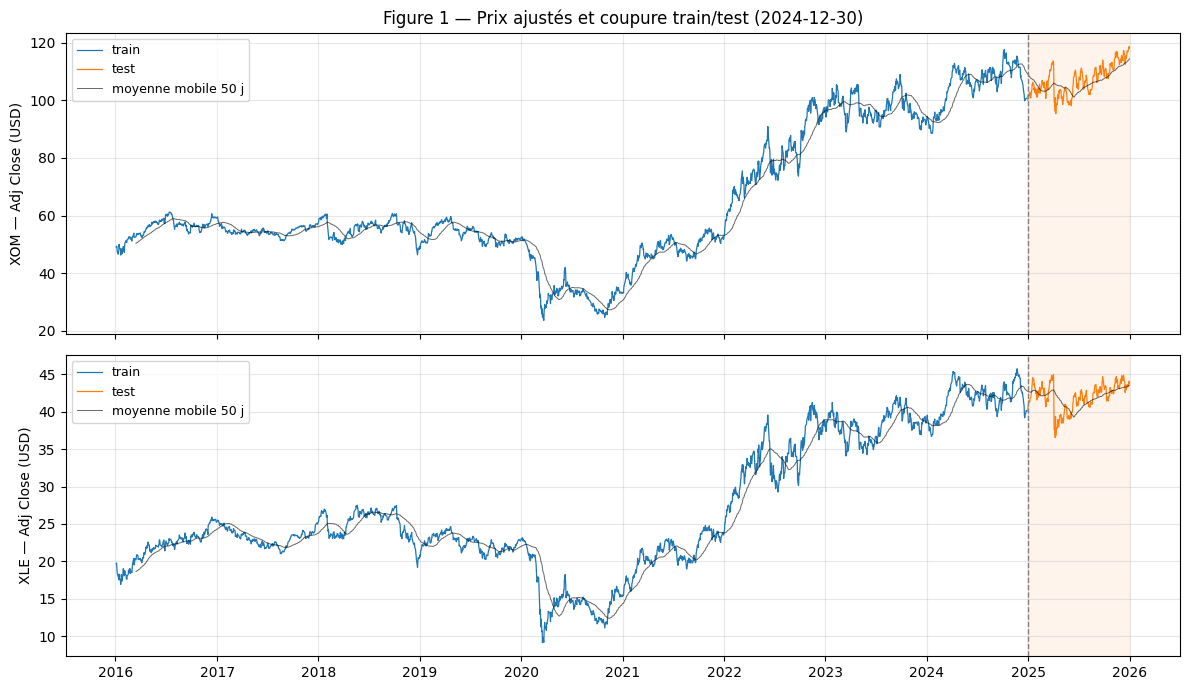

In [13]:
cut = test.index[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, tk in zip(axes, ["XOM", "XLE"]):
    ax.plot(train.index, train[f"{tk}_price"], color="tab:blue", lw=0.9, label="train")
    ax.plot(test.index, test[f"{tk}_price"], color="tab:orange", lw=0.9, label="test")
    ax.plot(panel.index, panel[f"{tk}_ma50"], color="black", lw=0.7, alpha=0.6, label="moyenne mobile 50 j")
    ax.axvspan(cut, panel.index[-1], color="tab:orange", alpha=0.08)
    ax.axvline(cut, color="grey", ls="--", lw=1)
    ax.set_ylabel(f"{tk} — Adj Close (USD)")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_title(f"Figure 1 — Prix ajustés et coupure train/test ({cut.date()})")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 1, "prix_train_test")
plt.show()

**Interprétation de la figure 1.**
- **Découpage.** Le train couvre **2 262 jours** (2016-01-04 → 2024-12-27), le test les **252 jours suivants** (2024-12-30 → 2025-12-31), soit environ une année de bourse complète.
- **Évolution des prix.** Les deux séries suivent la même trajectoire générale, avec deux ruptures nettes :
  - l'effondrement de 2020 (COVID, chute de la demande de pétrole) ;
  - la forte hausse de 2021–2022 (reprise puis guerre en Ukraine).

  Le parallélisme visuel entre XOM et XLE (corrélation des rendements journaliers : 0,914 sur toute la période) motive le test de cointégration de la section 3.2.
- **Conséquence pour la modélisation.** Le niveau des prix n'est manifestement pas stationnaire (tendance et ruptures). Les tests ADF/KPSS de la section 2 vérifieront formellement l'ordre d'intégration.
- **Point de vigilance : le test est plus calme que le train.** Le test contient bien un choc (chute brutale début avril 2025, visible sur les deux actifs), mais il est d'une ampleur sans commune mesure avec 2020 :

  | | Train | Test |
  | --- | --- | --- |
  | Écart-type des rendements XOM | 1,78 % | 1,48 % |
  | Volatilité réalisée maximale XOM | 108,9 % | 47,4 % |
  | Volatilité réalisée maximale XLE | 149,9 % | 61,1 % |

  Les erreurs de prévision mesurées sur le test seront donc conditionnelles à ce régime et ne se généraliseront pas automatiquement à une période de crise. On en tiendra compte dans la discussion des limites.

## 2. Analyse exploratoire

**Échantillon utilisé.** Les graphiques descriptifs couvrent toute la période. En revanche, tous les tests et outils qui servent à **choisir un modèle** (statistiques descriptives, ACF/PACF, STL, ADF/KPSS) sont calculés sur le **train uniquement** : identifier un modèle avec des données du test serait une fuite d'information.

In [14]:
from src import eda
from IPython.display import display

TRAIN = train  # 2 262 jours, 2016-01-04 → 2024-12-27
# Épisodes de crise repérés sur la figure 1, réutilisés pour annoter les graphiques.
CRISES = {"COVID-19": ("2020-02-20", "2020-04-30"), "Guerre en Ukraine": ("2022-02-24", "2022-06-30")}

def shade(ax, legend=False):
    for (name, (a, b)), color in zip(CRISES.items(), ["tab:red", "tab:purple"]):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=color, alpha=0.12, label=name if legend else None)
    ax.axvspan(test.index[0], test.index[-1], color="tab:orange", alpha=0.08, label="test" if legend else None)

### 2.1 Visualisation des séries

Les deux prix n'ont pas la même échelle (XOM ≈ 49 $ et XLE ≈ 20 $ en 2016) : on les ramène en **base 100** au 2016-01-04 pour comparer leurs trajectoires. On trace ensuite les rendements et la volatilité réalisée.

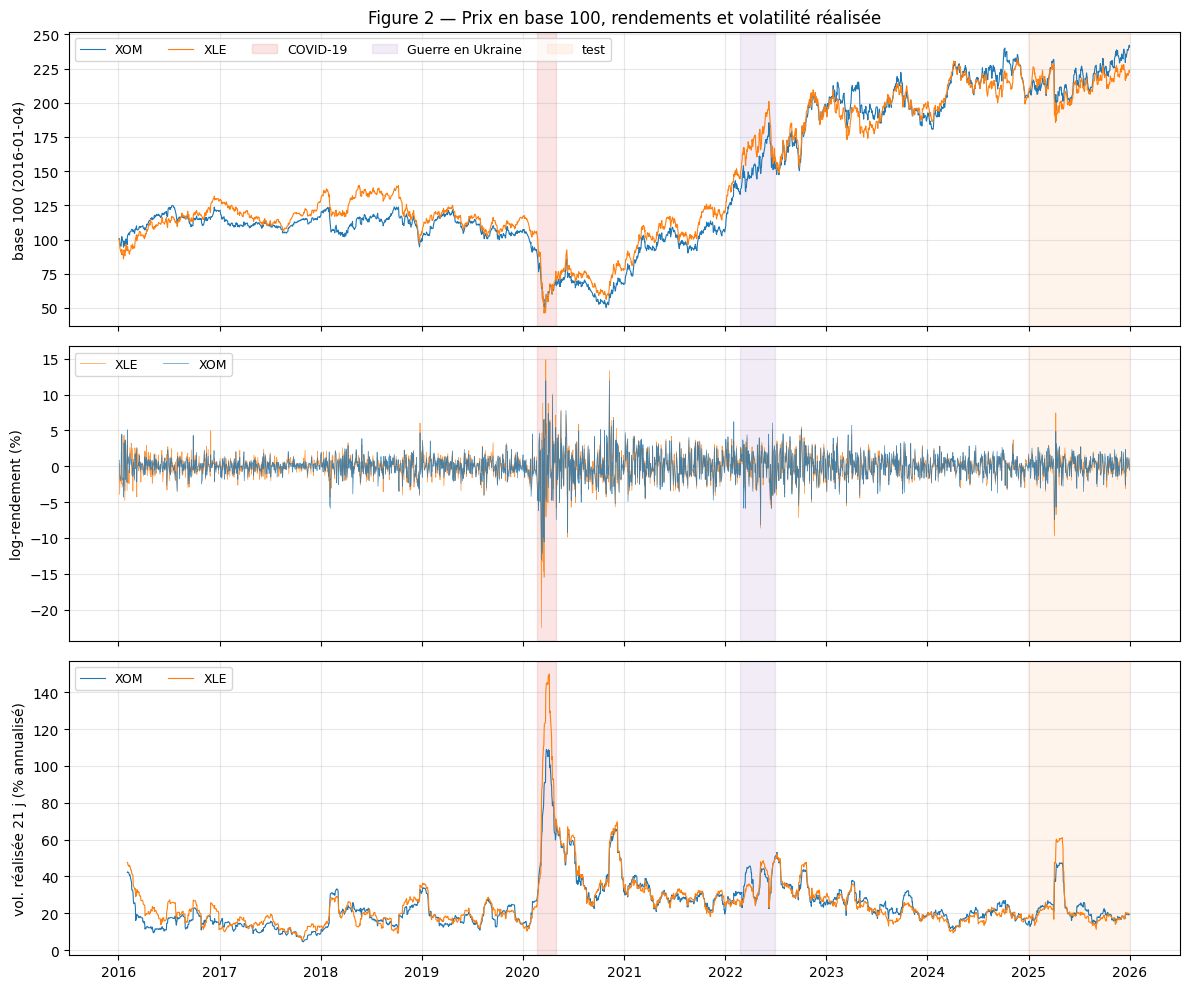

Performance totale 2016-2025 (dividendes réinvestis) : XOM 140.8 %, XLE 122.6 %
Creux et pics de volatilité réalisée :
  XOM : max 108.9 % le 2020-03-26 ; médiane 21.6 %
  XLE : max 149.9 % le 2020-04-06 ; médiane 21.2 %


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
base = panel[["XOM_price", "XLE_price"]] / panel[["XOM_price", "XLE_price"]].iloc[0] * 100
axes[0].plot(base.index, base["XOM_price"], lw=0.8, label="XOM")
axes[0].plot(base.index, base["XLE_price"], lw=0.8, label="XLE")
axes[0].set_ylabel("base 100 (2016-01-04)")
axes[1].plot(panel.index, panel["XLE_ret"], lw=0.5, color="tab:orange", alpha=0.8, label="XLE")
axes[1].plot(panel.index, panel["XOM_ret"], lw=0.5, color="tab:blue", alpha=0.8, label="XOM")
axes[1].set_ylabel("log-rendement (%)")
axes[2].plot(panel.index, panel["XOM_vol21"], lw=0.8, label="XOM")
axes[2].plot(panel.index, panel["XLE_vol21"], lw=0.8, label="XLE")
axes[2].set_ylabel("vol. réalisée 21 j (% annualisé)")
for i, ax in enumerate(axes):
    shade(ax, legend=(i == 0))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9, ncol=5)
axes[0].set_title("Figure 2 — Prix en base 100, rendements et volatilité réalisée")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 2, "series_rendements_volatilite")
plt.show()

perf = (base.iloc[-1] - 100).round(1)
print(f"Performance totale 2016-2025 (dividendes réinvestis) : XOM {perf['XOM_price']} %, XLE {perf['XLE_price']} %")
print("Creux et pics de volatilité réalisée :")
for tk in ["XOM", "XLE"]:
    v = panel[f"{tk}_vol21"]
    print(f"  {tk} : max {v.max():.1f} % le {v.idxmax().date()} ; médiane {v.median():.1f} %")

**Interprétation de la figure 2.**
- **Prix (base 100).** Sur 2016–2025, XOM progresse de **+140,8 %** et XLE de **+122,6 %** (dividendes réinvestis). Les deux trajectoires restent très proches, ce qui est attendu puisque XOM est l'une des plus grosses positions de l'ETF XLE. Deux ruptures se détachent :
  - le **krach de 2020**, où les deux actifs perdent environ la moitié de leur valeur ;
  - la **hausse de 2021–2022**, qui porte les prix à environ 200, soit le double de 2016.

  Ni l'un ni l'autre ne revient vers un niveau moyen fixe : visuellement, les prix ne sont pas stationnaires.
- **Rendements.** Au contraire des prix, ils oscillent autour de zéro sans tendance : ils ont l'allure d'une série stationnaire **en moyenne**. En revanche, leur amplitude varie fortement dans le temps :
  - une phase très calme en 2017 ;
  - une explosion en mars 2020, avec des chutes de −13 % (XOM) et −22,5 % (XLE) en une journée ;
  - une agitation durable en 2020–2022.

  C'est le phénomène de **regroupement de volatilité** (*volatility clustering*) : les fortes variations se suivent, les faibles aussi.
- **Volatilité réalisée.**
  - **Valeurs habituelles.** La médiane est de 21,6 % (XOM) et 21,2 % (XLE).
  - **Pics de mars–avril 2020.** La volatilité monte à **108,9 %** pour XOM (2020-03-26) et **149,9 %** pour XLE (2020-04-06), soit environ cinq fois la normale.
  - **2022.** L'agitation commence avec l'invasion de l'Ukraine (zone violette). Le pic de l'année arrive un peu plus tard (≈ 53 % pour les deux actifs le 2022-07-07) et reste deux à trois fois plus faible qu'en 2020.
  - **Avril 2025, dans le test.** On observe aussi un pic, autour de 50 à 60 %.
- **Conséquences pour la suite.** La moyenne des rendements semble stable, mais leur variance ne l'est pas. Il faudra donc :
  - modéliser le niveau en différences (à confirmer par ADF/KPSS en 2.6) ;
  - modéliser la variance conditionnelle avec un GARCH (section 3.3).

### 2.2 Statistiques descriptives des rendements (train)

Ces statistiques servent aussi d'entrée au prompt LLM de la section 5.

In [16]:
desc = eda.descriptive_stats(TRAIN[["XOM_ret", "XLE_ret"]])
save_table(desc, "tab04_stats_descriptives")
desc

,XOM_ret,XLE_ret
n,2261.0000,2261.0000
moyenne,0.0319,0.0315
écart-type,1.7845,1.9216
variance,3.1846,3.6925
skewness,-0.1630,-0.8902
excès de kurtosis,6.6224,16.4357
min,-13.0391,-22.4910
max,11.9442,14.8741
Jarque-Bera,4141.6970,25747.3428
p-value JB,0.0000,0.0000


**Interprétation des statistiques descriptives (train, 2 261 rendements).**

**Moyenne.** Le rendement moyen est de 0,032 % par jour, soit environ **8 % par an** pour les deux actifs (0,0319 × 252 et 0,0315 × 252). Il est minuscule face à l'écart-type journalier de 1,78 % (XOM) et 1,92 % (XLE), soit une volatilité annualisée de 28,3 % et 30,5 %. La statistique t de la moyenne vaut 0,0319 / (1,7845 / √2 261) ≈ **0,85** pour XOM (0,78 pour XLE) : la moyenne **n'est pas significativement différente de zéro**. Ce calcul suppose des rendements i.i.d. ; il est refait ci-dessous avec un écart-type robuste. On s'attend donc à ce que la constante (dérive) soit non significative dans les modèles ARIMA.

**Asymétrie.**
- Elle est négative pour les deux actifs : les fortes baisses sont plus marquées que les fortes hausses.
- Elle est faible pour XOM (skewness de −0,16) mais nette pour XLE (−0,89).
- Le minimum de XLE (−22,5 %) est bien plus extrême que son maximum (+14,9 %).

**Queues épaisses.** L'excès de kurtosis vaut **6,6** pour XOM et **16,4** pour XLE, contre 0 pour une loi normale. Les rendements extrêmes sont donc beaucoup plus fréquents que ne le prévoit une loi gaussienne.

**Normalité.** Le test de Jarque-Bera rejette très largement la normalité (JB = 4 142 pour XOM, 25 747 pour XLE ; p < 0,0001).

**Conséquences pour la modélisation.**
1. Les intervalles de prévision gaussiens des modèles ARIMA/VAR **sous-estimeront le risque de mouvements extrêmes**.
2. Le GARCH sera estimé avec une **loi de Student**, dont les queues épaisses sont adaptées.
3. Les tests de normalité des résidus rejetteront très probablement aussi. C'est attendu, et ne suffira pas à disqualifier un modèle.

In [17]:
# Le t classique suppose une variance constante, contredite par la figure 2 :
# on le recalcule avec un écart-type HAC (Newey-West), robuste à l'hétéroscédasticité et à l'autocorrélation.
mean_tests = pd.concat({tk: eda.mean_test(TRAIN[f"{tk}_ret"]) for tk in ["XOM", "XLE"]})
save_table(mean_tests, "tab04b_test_moyenne_hac")
mean_tests

moyenne  écart-type  statistique t  p-value
XOM classique (i.i.d.)           0.0319      0.0375         0.8487   0.3961
    HAC Newey-West (7 retards)   0.0319      0.0372         0.8561   0.3919
XLE classique (i.i.d.)           0.0315      0.0404         0.7786   0.4363
    HAC Newey-West (7 retards)   0.0315      0.0412         0.7630   0.4455

**Interprétation du test de moyenne robuste.**

**Pourquoi un écart-type robuste.** La statistique t précédente suppose des rendements indépendants et de variance constante, ce que contredit la figure 2. On refait donc le test H₀ : « rendement moyen nul » avec un écart-type **HAC de Newey-West** (7 retards, selon la règle usuelle ⌊4 (n/100)^(2/9)⌋), robuste à l'hétéroscédasticité et à l'autocorrélation.

**Résultat.** La conclusion ne change pas :

| | t classique | t HAC | p-value HAC |
| --- | --- | --- | --- |
| XOM | 0,85 | 0,86 | 0,39 |
| XLE | 0,78 | 0,76 | 0,45 |

La moyenne n'est pas significativement différente de zéro.

**Pourquoi les deux versions diffèrent si peu.** Pour une moyenne simple, la correction d'hétéroscédasticité seule ne modifie presque pas l'écart-type : elle compte surtout quand la variance est corrélée à un régresseur, ce qui n'est pas le cas ici. Et l'autocorrélation des rendements est trop faible pour peser.

**Conséquence.** Une dérive (constante) non significative est attendue dans les modèles ARIMA de la section 3.

### 2.3 Autocorrélations (ACF / PACF)

On examine trois transformations, dans l'ordre du plan : le **log-prix** (série brute), le **rendement** (série différenciée, puisque r_t = 100 × Δ ln P_t) et le **rendement au carré** (proxy de la variance). La bande bleue est l'intervalle de confiance à 95 % sous l'hypothèse de bruit blanc (≈ ±1,96/√n = ±0,041) : sur 40 retards, environ 2 la dépassent par pur hasard.

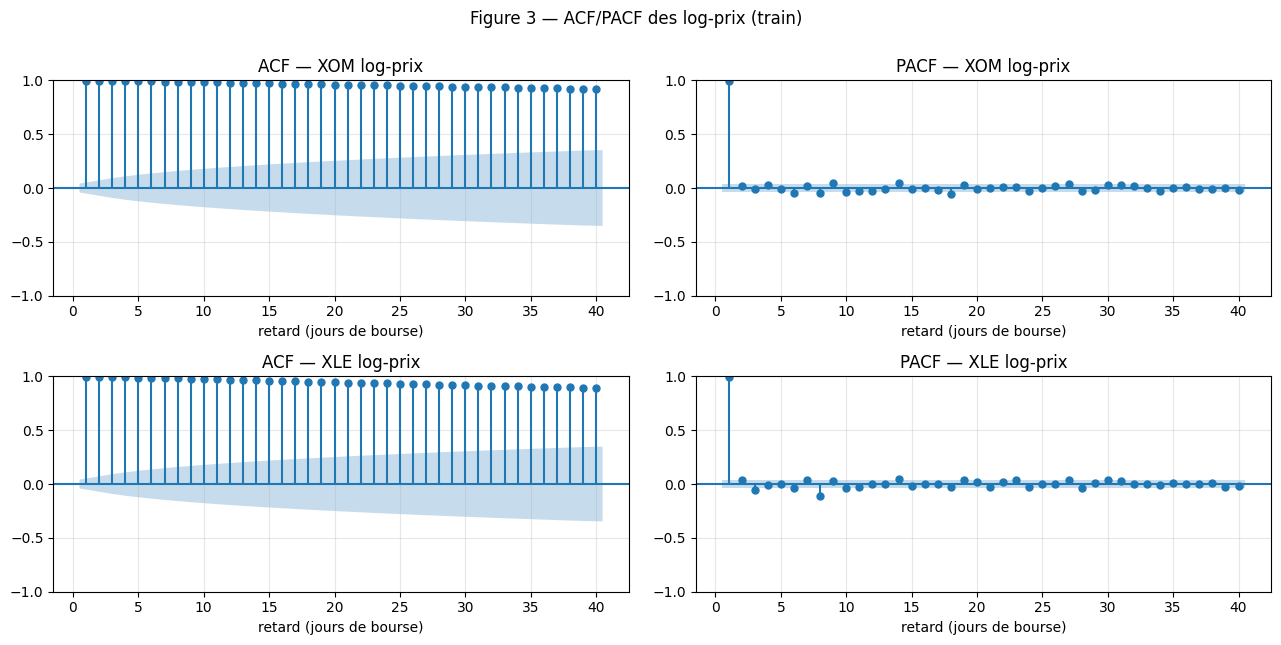

,XOM log-prix,XLE log-prix
n,2262,2262
bande 95 %,0.0412,0.0412
ACF(1),0.9982,0.9977
ACF(2),0.9965,0.9955
ACF(5),0.9913,0.9883
ACF(10),0.9820,0.9748
ACF(21),0.9589,0.9421
PACF(1),0.9982,0.9977
PACF(2),0.0176,0.0339
PACF(5),-0.0094,-0.0018


In [18]:
LAGS = 40
def acf_table(series):
    t = pd.DataFrame({name: eda.acf_summary(x, LAGS) for name, x in series.items()})
    return t

fig = eda.plot_acf_pacf({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]}, LAGS,
                        "Figure 3 — ACF/PACF des log-prix (train)")
save_fig(fig, 3, "acf_pacf_logprix")
plt.show()
acf_logp = acf_table({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]})
acf_logp

**Interprétation de la figure 3 (log-prix).**
- **ACF.** L'autocorrélation est quasi égale à 1 et décroît très lentement, de façon presque linéaire :
  - ACF(1) = 0,998 pour XOM (0,998 pour XLE) ;
  - ACF(21) = 0,959 (0,942), soit un mois plus tard ;
  - les **40 retards** restent tous très au-dessus de la bande de confiance.

  Cette décroissance lente est la signature d'une série **non stationnaire** : un choc ne s'efface pas, il se propage durablement au niveau des prix.
- **PACF.** Un seul pic, au retard 1 (0,998), puis plus rien : PACF(2) = 0,018 pour XOM (0,034 pour XLE). La série se comporte donc comme un AR(1) de coefficient ≈ 1, c'est-à-dire comme une **marche aléatoire** : l_t ≈ l_{t−1} + choc. Quelques retards partiels dépassent légèrement la bande (6 pour XOM, 5 pour XLE), mais avec des valeurs de 0,05 au plus, donc sans importance pratique.
- **Bande de confiance.** Sur le graphe ACF, la bande s'élargit avec le retard (formule de Bartlett). Le décompte « hors bande » du tableau utilise la bande fixe de bruit blanc (±0,041).
- **Ljung-Box.** Q(10) = 22 255 pour XOM (p < 0,0001) : l'absence d'autocorrélation est rejetée sans ambiguïté.

**Conclusion.** Le log-prix ne peut pas être modélisé tel quel par un ARMA stationnaire : il faut le différencier, ce que l'on vérifie sur la figure 4 et formellement en 2.6.

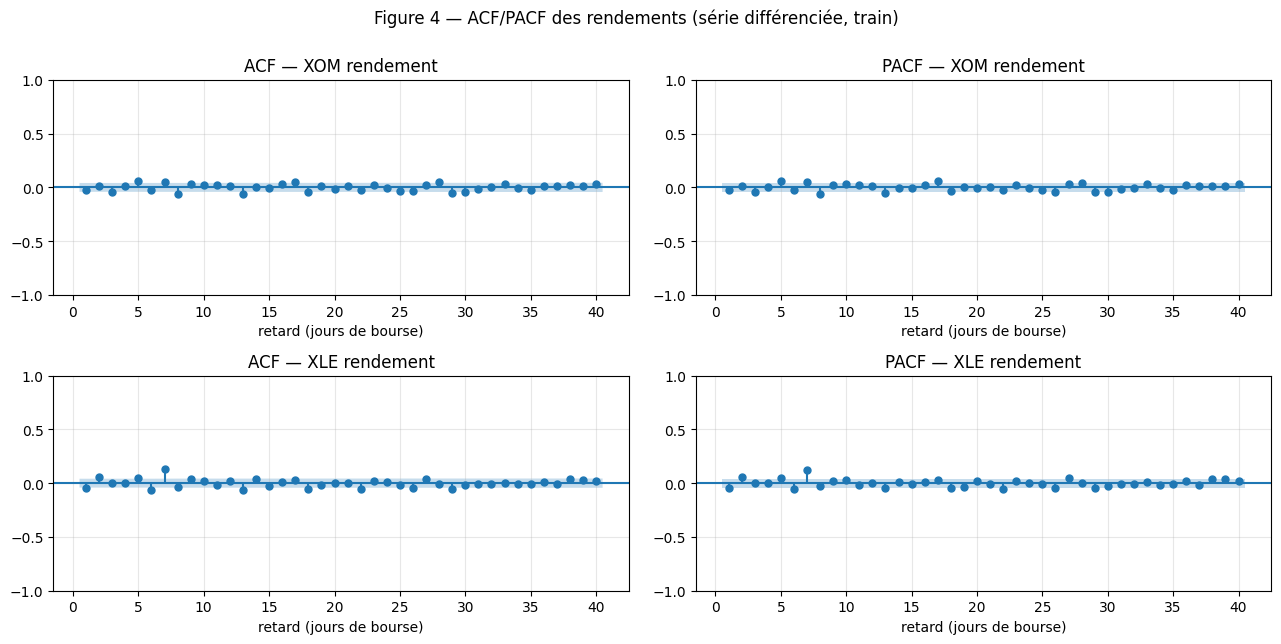

,XOM rendement,XLE rendement
n,2261,2261
bande 95 %,0.0412,0.0412
ACF(1),-0.0240,-0.0455
ACF(2),0.0140,0.0575
ACF(5),0.0579,0.0446
ACF(10),0.0262,0.0202
ACF(21),0.0164,-0.0005
PACF(1),-0.0240,-0.0455
PACF(2),0.0134,0.0556
PACF(5),0.0595,0.0450


In [19]:
fig = eda.plot_acf_pacf({"XOM rendement": TRAIN["XOM_ret"], "XLE rendement": TRAIN["XLE_ret"]}, LAGS,
                        "Figure 4 — ACF/PACF des rendements (série différenciée, train)")
save_fig(fig, 4, "acf_pacf_rendements")
plt.show()
acf_ret = acf_table({"XOM rendement": TRAIN["XOM_ret"], "XLE rendement": TRAIN["XLE_ret"]})
acf_ret

**Interprétation de la figure 4 (rendements = log-prix différencié).**
- **La structure de la figure 3 a disparu.** Une seule différenciation suffit à supprimer la persistance des niveaux. Les autocorrélations sont minuscules : la plus forte en valeur absolue vaut −0,064 (retard 8) pour XOM et 0,129 (retard 7) pour XLE. Une autocorrélation de 0,06 n'explique que 0,06² ≈ 0,4 % de la variance du rendement du lendemain.
- **Pas d'ordre ARMA lisible.** Ni l'ACF ni la PACF ne montrent de coupure nette après quelques retards :
  - les rares dépassements sont dispersés (XOM : retards 5, 7, 8, 13, 17, 28, 29, 30 ; XLE : 1, 2, 5, 6, 7, 13, 18, 22, 29) ;
  - aucun motif régulier ne s'en dégage.
- **Mais Ljung-Box rejette l'absence d'autocorrélation**, avec Q(10) = 34,9 pour XOM (p = 0,0001) et 70,1 pour XLE (p < 0,0001). Il y a 8 et 9 retards hors bande sur 40, alors qu'on en attend environ 2 par hasard. Avant d'en conclure qu'il existe une structure ARMA à exploiter, on vérifie d'où vient ce rejet dans le tableau suivant.

In [20]:
# Le rejet de Ljung-Box vient-il de la moyenne ou de la variance ? Trois versions des rendements.
robust = pd.concat({tk: eda.ljungbox_robustness(TRAIN[f"{tk}_ret"]) for tk in ["XOM", "XLE"]})
save_table(robust, "tab05_ljungbox_robustesse")
robust

p-value Q(5)  p-value Q(10)  p-value Q(20)
XOM rendements bruts                              0.0219         0.0001         0.0000
    standardisés par la vol. passée (21 j)        0.9714         0.9822         0.8980
    hors année 2020                               0.5890         0.4435         0.3595
XLE rendements bruts                              0.0050         0.0000         0.0000
    standardisés par la vol. passée (21 j)        0.4983         0.5343         0.7385
    hors année 2020                               0.6857         0.5099         0.8452

**Interprétation du contrôle de robustesse de Ljung-Box.**
Le test de Ljung-Box suppose une variance constante. Avec du regroupement de volatilité, quelques jours très agités suffisent à produire de grandes autocorrélations empiriques, et le test rejette trop souvent. On le refait donc sur deux versions corrigées des rendements :

| Version des rendements | XOM : p-value Q(10) | XLE : p-value Q(10) |
| --- | --- | --- |
| bruts | 0,0001 | < 0,0001 |
| divisés par leur volatilité des 21 jours précédents | **0,98** | **0,53** |
| sans l'année 2020 | **0,44** | **0,51** |

Le rejet **disparaît entièrement** dans les deux versions corrigées, pour Q(5), Q(10) et Q(20). Même le retard 7 de XLE, le plus marqué (0,129), tombe à 0,0008 sans 2020.

**Conclusion.**
- L'autocorrélation apparente des rendements est un **artefact de l'hétéroscédasticité de 2020**, pas une dynamique exploitable de la moyenne.
- En moyenne, les rendements sont compatibles avec un **bruit blanc**. Le log-prix est donc proche d'une marche aléatoire, et ARIMA(0,1,0) est le candidat de référence. Il sera comparé en 3.1 à des ARIMA(p,1,q) de petits ordres (p, q ≤ 2) et au choix d'`auto_arima`.
- Il faudra s'attendre à ce que les termes AR/MA éventuellement retenus aient un pouvoir prédictif très faible.

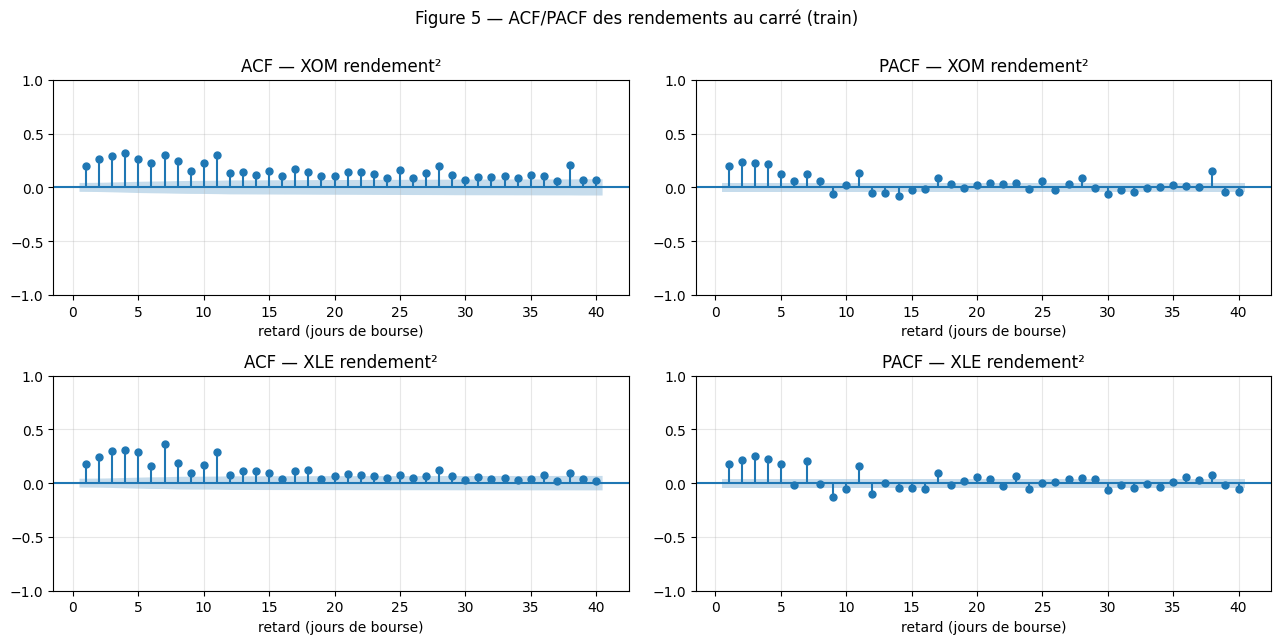

,XOM rendement²,XLE rendement²
n,2261,2261
bande 95 %,0.0412,0.0412
ACF(1),0.2028,0.1772
ACF(2),0.2673,0.2397
ACF(5),0.2645,0.2934
ACF(10),0.2227,0.1677
ACF(21),0.1434,0.0840
PACF(1),0.2028,0.1772
PACF(2),0.2359,0.2151
PACF(5),0.1256,0.1785


In [21]:
sq = {"XOM rendement²": TRAIN["XOM_ret"] ** 2, "XLE rendement²": TRAIN["XLE_ret"] ** 2}
fig = eda.plot_acf_pacf(sq, LAGS, "Figure 5 — ACF/PACF des rendements au carré (train)")
save_fig(fig, 5, "acf_pacf_rendements_carres")
plt.show()
acf_sq = acf_table(sq)
save_table(pd.concat([acf_logp, acf_ret, acf_sq], axis=1), "tab06_acf_resume")
acf_sq

**Interprétation de la figure 5 (rendements au carré).**
- **Le contraste avec la figure 4 est total.** Les rendements eux-mêmes sont quasi non autocorrélés, mais leurs carrés le sont fortement et durablement :
  - **XOM** : ACF(1) = 0,20 ; maximum 0,32 au retard 4 ; ACF(40) encore égale à 0,065 ; les **40 retards** dépassent la bande ;
  - **XLE** : maximum 0,37 au retard 7 ; 32 retards sur 40 hors bande ;
  - **Ljung-Box** : Q(10) = 1 464 pour XOM et 1 343 pour XLE (p < 0,0001).
- **Lecture économique.** Un jour de forte variation, dans un sens ou dans l'autre, est suivi d'autres jours de forte variation : c'est la mesure chiffrée du regroupement de volatilité de la figure 2. La décroissance lente de l'ACF indique une volatilité **très persistante**.
- **Implication pour le modèle.** La PACF des carrés est significative sur les ~5 premiers retards (entre 0,13 et 0,25), ce qui correspondrait à un ARCH d'ordre élevé. Un **GARCH(1,1)** représente cette dynamique de façon beaucoup plus parcimonieuse : la variance d'aujourd'hui dépend du choc d'hier **et** de la variance d'hier. Ce diagnostic justifie la section 3.3.
- **Un rendement non autocorrélé n'est pas un rendement indépendant.** Ces rendements sont imprévisibles en moyenne (figure 4), mais leur amplitude est en partie prévisible.

### 2.4 Décomposition STL du log-prix (train)

STL (Seasonal-Trend decomposition using Loess) en version **robuste**, pour que les chocs de 2020 ne déforment pas la tendance et la saisonnalité. On décompose le log-prix, et non le prix, pour que les composantes soient additives : une variation de la composante correspond à un pourcentage du prix.
Trois périodes sont testées : **5** (semaine de bourse), **21** (mois de bourse) et **252** (année de bourse). Pour juger objectivement la saisonnalité, on calcule la **force** de chaque composante (Wang, Smith & Hyndman, 2006) : F = max(0, 1 − Var(résidu) / Var(composante + résidu)). F proche de 0 signifie une composante inexistante, F proche de 1 une composante dominante.

In [22]:
strength = pd.DataFrame({(tk, p): eda.stl_strength(eda.stl_decompose(TRAIN[f"{tk}_logp"], p))
                         for tk in ["XOM", "XLE"] for p in (5, 21, 252)}).T
strength.index.names = ["actif", "période"]
save_table(strength, "tab07_stl_force")
strength

force tendance F_T  force saisonnalité F_S  amplitude saisonnière (max - min)  écart-type résidu
actif période                                                                                                  
XOM   5                    0.9968                  0.0000                             0.0978             0.0201
      21                   0.9912                  0.0319                             0.1313             0.0332
      252                  0.8686                  0.0000                             0.4105             0.1283
XLE   5                    0.9955                  0.0000                             0.2300             0.0218
      21                   0.9859                  0.0199                             0.1466             0.0386
      252                  0.8559                  0.0012                             0.3169             0.1231

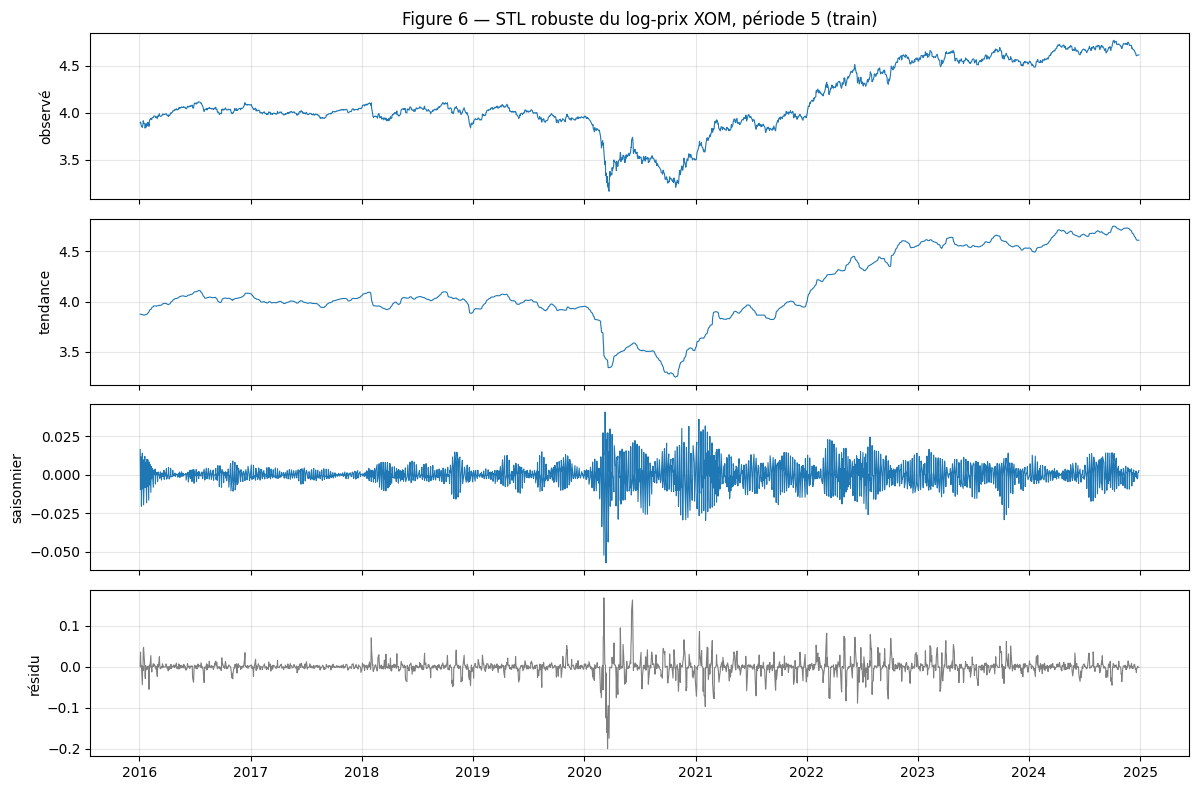

In [23]:
stl5 = eda.stl_decompose(TRAIN["XOM_logp"], 5)
fig = eda.plot_stl(stl5, "Figure 6 — STL robuste du log-prix XOM, période 5 (train)")
save_fig(fig, 6, "stl_xom_p5")
plt.show()

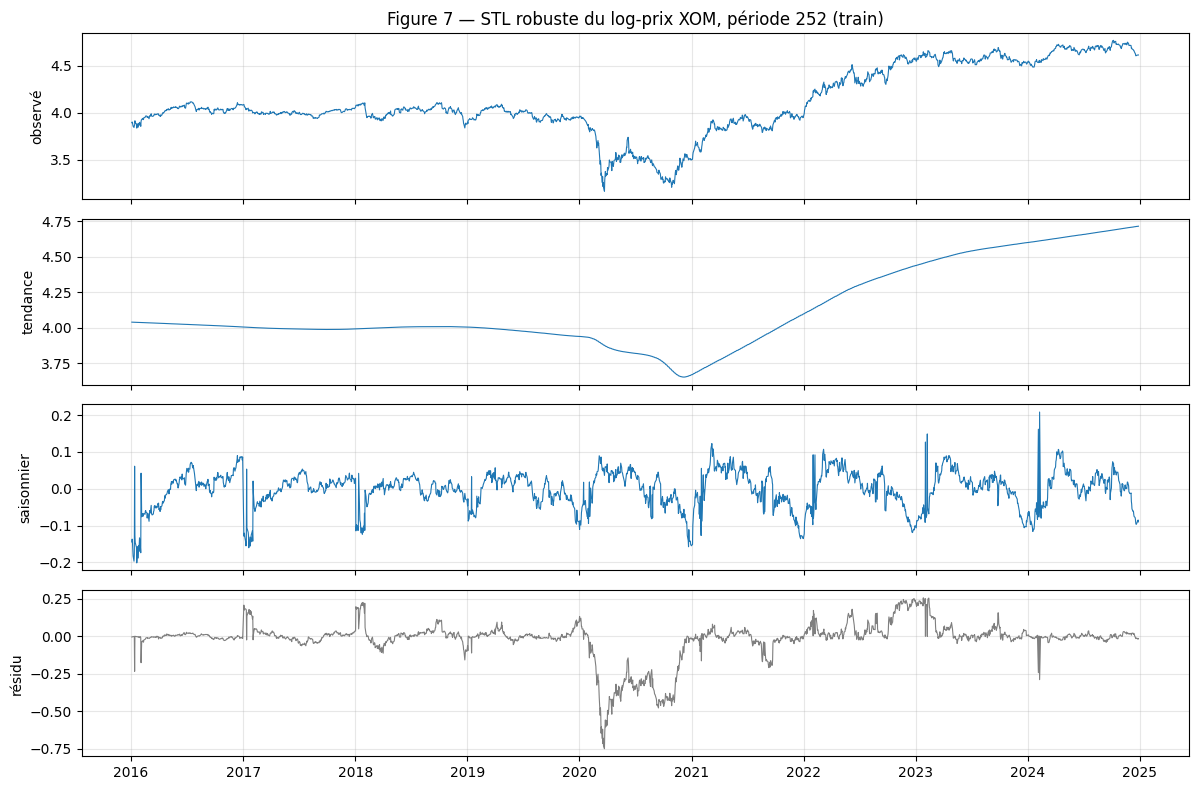

In [24]:
stl252 = eda.stl_decompose(TRAIN["XOM_logp"], 252)
fig = eda.plot_stl(stl252, "Figure 7 — STL robuste du log-prix XOM, période 252 (train)")
save_fig(fig, 7, "stl_xom_p252")
plt.show()

In [25]:
# Contre-vérification de la saisonnalité hebdomadaire directement sur les rendements :
# un effet « jour de la semaine » est la forme que prendrait une saisonnalité s = 5.
for tk in ["XOM", "XLE"]:
    w = eda.weekday_effect(TRAIN[f"{tk}_ret"])
    print(f"{tk} — Kruskal-Wallis (moyennes) : stat = {w['Kruskal-Wallis stat']:.3f}, p = {w['Kruskal-Wallis p']:.4f} ; "
          f"Levene (variances) : stat = {w['Levene stat']:.3f}, p = {w['Levene p']:.4f}")
    display(w["table"].round(3).T)

XOM — Kruskal-Wallis (moyennes) : stat = 2.806, p = 0.5909 ; Levene (variances) : stat = 1.275, p = 0.2775


,lundi,mardi,mercredi,jeudi,vendredi
mean,0.1130,0.0630,-0.0180,0.0190,-0.0110
std,2.0280,1.7320,1.7540,1.7090,1.7070
count,419.0000,465.0000,463.0000,458.0000,456.0000


XLE — Kruskal-Wallis (moyennes) : stat = 1.735, p = 0.7843 ; Levene (variances) : stat = 2.592, p = 0.0350


,lundi,mardi,mercredi,jeudi,vendredi
mean,0.0650,0.0480,-0.0170,-0.0140,0.0780
std,2.3520,1.7580,1.9470,1.7820,1.7490
count,419.0000,465.0000,463.0000,458.0000,456.0000


**Interprétation de la décomposition STL.**

**Force des composantes (tableau).** La tendance domine dans tous les cas : F_T = 0,997 (période 5), 0,991 (21) et 0,869 (252) pour XOM, avec des valeurs proches pour XLE. La saisonnalité est **inexistante** : F_S = 0,000, 0,032 et 0,000 pour XOM, et 0,000, 0,020 et 0,001 pour XLE. Aucune période testée ne fait apparaître de cycle exploitable.

**Figure 6 (période 5).**
- **Tendance.** Elle reproduit fidèlement le log-prix : une phase plate de 2016 à 2019, la chute de 2020, puis la remontée de 2021–2022.
- **« Saisonnalité ».** Une vraie saisonnalité hebdomadaire répéterait le même motif chaque semaine, avec une amplitude stable. Ici, l'amplitude de la composante suit exactement la volatilité : quasi nulle en 2017, maximale le 2020-03-13 (|s| = 0,057). STL a simplement découpé une partie du bruit en blocs de 5 jours.
- **Ordres de grandeur.** L'écart-type de cette composante (0,008) reste bien inférieur à celui du résidu (0,020).
- **Résidu.** Il concentre les chocs de 2020 et a l'allure des rendements.

**Figure 7 (période 252).**
- **Tendance.** Une fenêtre d'un an la rend très lisse.
- **« Saisonnalité ».** La composante ne répète aucun profil annuel identifiable, et ses pics isolés ne reviennent pas à la même date d'une année sur l'autre.
- **Résidu.** Il absorbe le krach de 2020 (jusqu'à −0,75 en log, soit environ −53 %) et des écarts de ±0,25. Son écart-type (0,128) est six fois celui de la décomposition hebdomadaire.

Une décomposition annuelle ne décrit donc pas ces données.

**Contre-vérification directe.** Une saisonnalité de période 5 se traduirait par un effet « jour de la semaine » sur les rendements.
- **Moyenne.** Le lundi a le rendement moyen le plus élevé (0,113 % pour XOM), mais avec l'écart-type le plus fort (2,03 %). Le test de Kruskal-Wallis ne détecte **aucune différence** entre jours (p = 0,59 pour XOM, 0,78 pour XLE).
- **Variance.** Le test de Levene ne rejette pas pour XOM (p = 0,28). Il rejette de justesse pour XLE (p = 0,035), dont le lundi est un peu plus volatil (écart-type de 2,35 % contre 1,75 à 1,95 % les autres jours), ce qui est cohérent avec l'accumulation d'informations pendant le week-end.

Cela concerne la **variance**, pas la moyenne : ce n'est pas un motif qu'un SARIMA pourrait modéliser.

**Conclusion.**
- Il n'y a **pas de saisonnalité** à modéliser : D = 0.
- Le SARIMA de période s = 5 sera estimé en 3.1 pour le vérifier formellement, et devrait être écarté.
- La tendance n'est pas une droite déterministe : elle erre, monte et chute. C'est le comportement d'une tendance **stochastique** (racine unitaire), testée en 2.6.

### 2.5 Valeurs aberrantes

**Méthode.** Un rendement est signalé s'il sort de [Q1 − 3·IQR ; Q3 + 3·IQR], où les quartiles sont calculés sur les **63 jours de bourse précédents** (un trimestre).
- **Seuil glissant plutôt que fixe** : la règle s'adapte au régime de volatilité. Un mouvement de 4 % est banal en mars 2020 mais exceptionnel en 2017.
- **Fenêtre décalée d'un jour** (`shift(1)`) : le jour testé n'influence pas son propre seuil, et la règle n'utilise que le passé.
- **k = 3** (et non 1,5) : avec des queues aussi épaisses, k = 1,5 signalerait des centaines de jours parfaitement ordinaires.

La détection est faite sur toute la période, car la variable indicatrice doit exister aussi sur le test.

In [26]:
out = {tk: eda.detect_outliers(panel[f"{tk}_ret"]) for tk in ["XOM", "XLE"]}
counts = pd.DataFrame({tk: o["outlier"].groupby(o.index.year).sum() for tk, o in out.items()}).fillna(0).astype(int)
counts.loc["total"] = counts.sum()
counts.loc["dont test"] = [int(o.loc[test.index, "outlier"].sum()) for o in out.values()]
both = (out["XOM"]["outlier"] & out["XLE"]["outlier"])
print(f"Jours signalés simultanément pour XOM et XLE : {int(both.sum())}")
counts.T

Jours signalés simultanément pour XOM et XLE : 11


Date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,total,dont test
XOM,1,0,2,0,10,0,0,0,0,2,15,2
XLE,1,0,2,0,10,0,1,0,0,4,18,4


In [27]:
rows = []
for tk, o in out.items():
    f = o[o["outlier"] == 1]
    rows.append(f.assign(actif=tk, échantillon=np.where(f.index.isin(test.index), "test", "train")))
outliers = pd.concat(rows).reset_index().sort_values(["actif", "Date"])
outliers = outliers[["actif", "Date", "échantillon", "rendement", "borne basse", "borne haute"]]
save_table(outliers, "tab08_outliers", index=False)

# Variables indicatrices sauvegardées pour les modèles (ex. régresseur d'intervention en ARIMAX).
flags = pd.DataFrame({f"{tk}_outlier": o["outlier"] for tk, o in out.items()})
flags.to_csv(ROOT / "data/processed/outliers.csv", lineterminator="\n")
outliers.round(2)

,actif,Date,échantillon,rendement,borne basse,borne haute
15,XLE,2016-11-30,train,4.9600,-4.3800,4.2800
16,XLE,2018-02-02,train,-4.2700,-3.5500,4.0100
17,XLE,2018-02-05,train,-4.2900,-3.6100,4.0100
18,XLE,2020-02-27,train,-5.5000,-4.7400,4.2800
19,XLE,2020-03-06,train,-5.7800,-5.5500,5.3000
20,XLE,2020-03-09,train,-22.4900,-5.5200,5.0300
21,XLE,2020-03-12,train,-13.3200,-5.9600,5.3600
22,XLE,2020-03-13,train,8.8300,-6.2400,5.5700
23,XLE,2020-03-16,train,-14.6300,-6.6600,6.1300
24,XLE,2020-03-18,train,-15.5000,-6.9000,6.2700


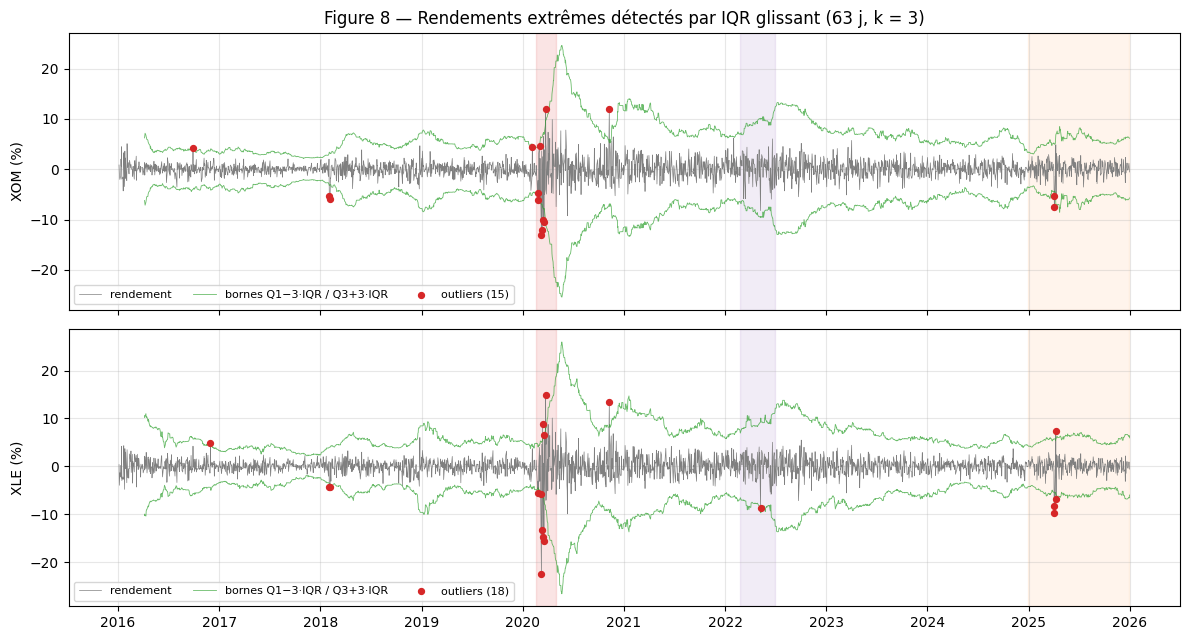

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, (tk, o) in zip(axes, out.items()):
    ax.plot(o.index, o["rendement"], lw=0.5, color="grey", label="rendement")
    ax.plot(o.index, o["borne haute"], lw=0.6, color="tab:green", alpha=0.7, label="bornes Q1−3·IQR / Q3+3·IQR")
    ax.plot(o.index, o["borne basse"], lw=0.6, color="tab:green", alpha=0.7)
    f = o[o["outlier"] == 1]
    ax.scatter(f.index, f["rendement"], color="tab:red", s=18, zorder=3, label=f"outliers ({len(f)})")
    shade(ax)
    ax.set_ylabel(f"{tk} (%)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8, ncol=3)
axes[0].set_title("Figure 8 — Rendements extrêmes détectés par IQR glissant (63 j, k = 3)")
fig.tight_layout()
save_fig(fig, 8, "outliers")
plt.show()

**Interprétation des valeurs aberrantes.**

**Bilan.** On détecte 15 jours extrêmes pour XOM (13 dans le train, 2 dans le test) et 18 pour XLE (14 et 4). **11 jours** sont communs aux deux actifs, ce qui confirme qu'il s'agit de chocs de marché et non d'erreurs de données propres à un titre.

**Concentration en 2020.** Dix jours par actif tombent en 2020. Les plus violents sont :
- **2020-03-09** : −13,0 % pour XOM, −22,5 % pour XLE, face à des bornes de −6,9 % et −5,5 %. Ce jour-là, après l'échec des négociations OPEP+, l'Arabie saoudite lance une guerre des prix contre la Russie, en pleine propagation du COVID-19 : le Brent subit sa plus forte baisse en une séance depuis 1991 ([KVIA / CNN Business](https://kvia.com/news/business-technology/2020/03/09/oil-crashes-by-most-since-1991-as-saudi-arabia-launches-price-war/)). Notre propre série du Brent (`BZ=F`) perd −24,1 % ce jour-là, exactement la baisse à la clôture rapportée par la presse : la date et la donnée sont recoupées ;
- les 12, 16 et 18 mars, puis le rebond du 24 mars (+11,9 % pour XOM, +14,9 % pour XLE) ;
- **2020-11-09** (+11,9 % et +13,3 %) : Pfizer et BioNTech annoncent que leur vaccin contre le COVID-19 est efficace à plus de 90 % d'après les premiers résultats de phase 3, ce qui déclenche une forte hausse du pétrole et des valeurs énergétiques ([PBS NewsHour](https://www.pbs.org/newshour/world/global-markets-rocket-higher-amid-vaccine-news-and-u-s-election)).

**Dans le test.** Les jours détectés se concentrent sur **3 au 10 avril 2025** : chute de −7,5 % pour XOM et de −9,7 % pour XLE le 4 avril, puis rebond de +7,5 % pour XLE le 9 avril. Cette séquence suit exactement le calendrier des droits de douane américains : annonce des tarifs « réciproques » le 2 avril après la clôture, chute des marchés les 3 et 4 avril, suspension de 90 jours annoncée le 9 avril, nouvelle baisse le 10 avril ([Wikipedia, « 2025 stock market crash »](https://en.wikipedia.org/wiki/2025_stock_market_crash)). Les quatre jours signalés pour XLE (3, 4, 9 et 10 avril) correspondent un à un à ces étapes.

Toutes les sources sont regroupées dans `docs/sources.md`.

**Une limite de la règle.** La figure montre qu'après mars 2020 les bornes s'élargissent jusqu'à environ ±25 %, parce que le trimestre précédent était lui-même extrême. Des baisses importantes ne sont donc pas signalées :
- −7,4 % pour XOM le 2020-05-01 (borne à −22,5 %) ;
- −9,2 % pour XOM et −9,9 % pour XLE le 2020-06-11 (bornes à −18,1 % et −20,1 %). Une règle glissante juge chaque jour **par rapport à son régime** : c'est voulu, mais elle réagit avec retard aux changements de régime.

**Traitement retenu : conservation, avec une variable indicatrice.**
1. **Ces chocs sont réels.** Ils correspondent à des événements de marché identifiables et se retrouvent sur les deux actifs. Ce ne sont pas des erreurs de mesure.
2. **Les supprimer ou les lisser sous-estimerait le risque.** La volatilité est justement ce que modélise GARCH : retirer les jours extrêmes ferait disparaître l'objet même de l'étude, et donnerait des intervalles de prévision trop étroits.
3. **Les remplacer serait un choix arbitraire.** Le remplacement par une médiane ou par interpolation créerait des données qui n'ont jamais existé.

Les indicatrices `XOM_outlier` et `XLE_outlier` sont sauvegardées dans `data/processed/outliers.csv`. Elles pourront servir de variables d'intervention (ARIMAX), ou à tester la sensibilité des résultats aux jours extrêmes.

**Sensibilité aux paramètres.** La fenêtre (63 jours) et le seuil (k = 3) sont des choix. On refait la détection sur une grille de 16 réglages, avec des fenêtres de 21, 63, 126 et 252 jours et k = 2 ; 2,5 ; 3 ; 3,5. On regarde ensuite :
- combien de jours chaque réglage signale ;
- quels jours restent signalés quel que soit le réglage : le **noyau**, défini comme les jours signalés par au moins 12 des 16 réglages.

In [29]:
sens = {tk: eda.outlier_sensitivity(panel[f"{tk}_ret"], test.index) for tk in ["XOM", "XLE"]}
grid = pd.concat({tk: g for tk, (g, _) in sens.items()})
save_table(grid, "tab08b_outliers_sensibilite")
grid.unstack("k")["total"]

k            2.0000  2.5000  3.0000  3.5000
    fenêtre                                
XOM 21           65      33      18      11
    63           40      23      15      11
    126          49      26      17      12
    252          54      31      21      15
XLE 21           66      29      14      11
    63           49      30      18      15
    126          59      34      24      16
    252          56      36      27      20

In [30]:
core = pd.concat({tk: c for tk, (_, c) in sens.items()})
core.index.names = ["actif", "Date"]
save_table(core, "tab08c_outliers_noyau")
for tk, (g, c) in sens.items():
    ref = int(out[tk]["outlier"].sum())
    print(f"{tk} : noyau de {len(c)} jours, tous dans la référence : {bool(c['dans la référence'].all())} "
          f"(référence = {ref} jours, dont {ref - len(c)} hors noyau)")
core.round(2)

XOM : noyau de 11 jours, tous dans la référence : True (référence = 15 jours, dont 4 hors noyau)
XLE : noyau de 14 jours, tous dans la référence : True (référence = 18 jours, dont 4 hors noyau)


rendement  réglages qui le signalent  dans la référence
actif Date                                                               
XOM   2018-02-02    -5.2300                         16               True
      2018-02-05    -5.8600                         16               True
      2020-02-27    -6.2100                         14               True
      2020-03-09   -13.0400                         12               True
      2020-03-12   -12.1400                         12               True
      2020-03-16   -10.0100                         12               True
      2020-03-18   -10.5600                         12               True
      2020-03-24    11.9400                         12               True
      2020-11-09    11.9200                         16               True
      2025-04-03    -5.4000                         13               True
      2025-04-04    -7.4700                         16               True
XLE   2018-02-02    -4.2700                         15               True
      2018-02-05    -4.2900                         14               True
      2020-02-27    -5.5000                         12               True
      2020-03-09   -22.4900                         16               True
      2020-03-12   -13.3200                         12               True
      2020-03-13     8.8300                         12               True
      2020-03-16   -14.6300                         13               True
      2020-03-18   -15.5000                         12               True
      2020-03-24    14.8700                         13               True
      2020-11-09    13.3400                         16               True
      2025-04-03    -8.1800                         16               True
      2025-04-04    -9.6500                         16               True
      2025-04-09     7.4600                         16               True
      2025-04-10    -6.7600                         15               True

**Interprétation de la sensibilité.**

**Le nombre de jours signalés dépend beaucoup des paramètres.** Selon le réglage, on obtient de 11 à 65 jours pour XOM et de 11 à 66 pour XLE. Les deux paramètres jouent :
- **k = 2** produit 40 à 66 signalements, dont beaucoup de mouvements ordinaires pour des queues aussi épaisses ;
- **une fenêtre de 21 jours** s'adapte si vite au régime qu'elle ne retrouve qu'environ la moitié des jours de la référence.

Le nombre « 15 outliers » n'a donc pas de valeur absolue : il dépend de la définition retenue.

**Mais les jours importants sont robustes.** Le **noyau**, signalé par au moins 12 des 16 réglages, compte **11 jours pour XOM et 14 pour XLE**, et notre réglage de référence (63 jours, k = 3) les retrouve **tous**. Ce sont :
- les deux séances de début février 2018 ;
- les journées de mars 2020 : le 27 février, puis les 9, 12, 16, 18 et 24 mars, plus le 13 mars pour XLE ;
- le 9 novembre 2020 ;
- avril 2025 : les 3 et 4 avril pour XOM, ainsi que les 9 et 10 pour XLE.

Les **4 jours** de la référence qui restent hors du noyau, pour chaque actif, sont des cas limites dont le statut dépend du réglage :
- XOM : 2016-09-28, 2020-02-05, 2020-02-24, 2020-03-02 ;
- XLE : 2016-11-30, 2020-03-06, 2020-03-19, 2022-05-09.

**Conséquence pratique limitée.** Comme les outliers sont **conservés** dans toutes les estimations, le choix des paramètres n'affecte que la variable indicatrice, pas les données des modèles. Si l'indicatrice est utilisée comme régresseur, il sera prudent de vérifier que les résultats tiennent avec la version « noyau » (`tab08c_outliers_noyau.csv`).

### 2.6 Tests de stationnarité : ADF et KPSS (train)

Les deux tests sont complémentaires car leurs **hypothèses nulles sont opposées** :
- **ADF** (Dickey-Fuller augmenté) : H₀ = la série a une racine unitaire (non stationnaire). Le nombre de retards augmentés est choisi par AIC, pour absorber l'autocorrélation des résidus du test.
- **KPSS** : H₀ = la série est stationnaire (autour d'une constante, ou d'une tendance déterministe dans la spécification « constante + tendance »). Le nombre de retards de la variance de long terme est choisi automatiquement (Hobijn et al., 1998).

Chaque série est testée avec deux spécifications. La spécification « constante + tendance » est la plus exigeante pour le log-prix, qui présente une dérive visible : elle vérifie qu'il ne s'agit pas d'une simple tendance déterministe.
Décision au seuil de 5 % : ADF rejette H₀ si sa statistique est **inférieure** à la valeur critique, KPSS si sa statistique est **supérieure** à la sienne.

In [31]:
stationarity = eda.stationarity_table({
    "XOM log-prix": TRAIN["XOM_logp"], "XOM rendement": TRAIN["XOM_ret"],
    "XLE log-prix": TRAIN["XLE_logp"], "XLE rendement": TRAIN["XLE_ret"],
})
save_table(stationarity, "tab09_adf_kpss")
stationarity.round(4)

ADF stat  ADF VC 5 %  ADF retards   ADF p  ADF rejette H0  KPSS stat  KPSS VC 5 %  KPSS retards  KPSS p  KPSS rejette H0  \
série         spécification                                                                                                                                    
XOM log-prix  constante              -0.9714     -2.8628           18  0.7635           False     3.5632       0.4630            29  < 0.01             True   
              constante + tendance   -1.5995     -3.4124           18  0.7926           False     1.3972       0.1460            29  < 0.01             True   
XOM rendement constante             -10.5566     -2.8628           17  0.0000            True     0.1439       0.4630             8  > 0.10            False   
              constante + tendance  -10.5684     -3.4124           17  0.0000            True     0.0845       0.1460             8  > 0.10            False   
XLE log-prix  constante              -1.5033     -2.8628            7  0.5319           False     3.5858       0.4630            29  < 0.01             True   
              constante + tendance   -1.9726     -3.4124            7  0.6163           False     1.2637       0.1460            29  < 0.01             True   
XLE rendement constante             -16.0638     -2.8628            6  0.0000            True     0.0840       0.4630             9  > 0.10            False   
              constante + tendance  -16.0600     -3.4124            6  0.0000            True     0.0607       0.1460             9  > 0.10            False   

                                                         conclusion  
série         spécification                                          
XOM log-prix  constante             non stationnaire : différencier  
              constante + tendance  non stationnaire : différencier  
XOM rendement constante                                stationnaire  
              constante + tendance                     stationnaire  
XLE log-prix  constante             non stationnaire : différencier  
              constante + tendance  non stationnaire : différencier  
XLE rendement constante                                stationnaire  
              constante + tendance                     stationnaire

**Interprétation des tests ADF et KPSS (train).**

**Log-prix : non stationnaires.**
- **XOM, spécification constante.** L'ADF vaut −0,97, alors que la valeur critique à 5 % est −2,86, avec 18 retards et p = 0,76 : la racine unitaire **n'est pas rejetée**. Le KPSS vaut 3,56, très au-dessus de la valeur critique de 0,463 (p < 0,01) : la stationnarité **est rejetée**.
- **XOM, spécification constante + tendance.** Même verdict : ADF −1,60 contre −3,41 (p = 0,79) ; KPSS 1,40 contre 0,146 (p < 0,01). Le log-prix n'est donc **pas non plus stationnaire autour d'une tendance déterministe**, et retirer une droite ne suffirait pas.
- **XLE.** Résultats identiques : ADF −1,50 (p = 0,53) et −1,97 (p = 0,62) ; KPSS 3,59 et 1,26.
- **Les deux tests concordent** : selon le tableau de décision du plan, conclusion « non stationnaire : différencier ».

**Rendements (log-prix différencié) : stationnaires.**
- **ADF.** La racine unitaire est massivement rejetée : −10,56 pour XOM et −16,06 pour XLE, contre −2,86 (p < 0,0001).
- **KPSS.** La stationnarité n'est pas rejetée : 0,144 pour XOM et 0,084 pour XLE, contre 0,463 (p > 0,10).
- **Les deux spécifications** donnent la même conclusion, et les deux tests concordent : **stationnaire**.

**Fiabilité.** Toutes les statistiques sont loin de leurs valeurs critiques : les conclusions ne dépendent ni du seuil choisi ni de la spécification. Le nombre élevé de retards retenus par AIC (18 pour l'ADF de XOM, 29 pour le KPSS des log-prix) reflète la persistance et l'hétéroscédasticité de la série. Ce choix rend le test robuste à l'autocorrélation, sans changer la décision.

Dernière question : la non-stationnarité du log-prix ne serait-elle qu'un effet du krach de 2020 ?

In [32]:
# Robustesse : la non-stationnarité du log-prix n'est-elle qu'un effet du krach de 2020 ?
za = eda.zivot_andrews_table({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]})
save_table(za, "tab10_zivot_andrews")
za.round(4)

statistique  valeur critique 5 %  p-value  retards date de rupture estimée  H0 rejetée (5 %)
série        spécification                                                                                                              
XOM log-prix rupture de niveau                  -3.7940              -4.8107   0.4831       18              2021-12-20             False
             rupture de niveau et de pente      -4.2081              -5.0733   0.3688       18              2020-01-06             False
XLE log-prix rupture de niveau                  -3.9725              -4.8107   0.3685        7              2021-12-20             False
             rupture de niveau et de pente      -4.5680              -5.0733   0.1839        7              2020-01-07             False

**Interprétation du test de Zivot-Andrews.** Une série stationnaire autour d'une tendance qui **casse** une fois peut ressembler à une marche aléatoire, et l'ADF ne rejette alors pas la racine unitaire à tort (Perron, 1989). Zivot-Andrews teste la racine unitaire contre une alternative **stationnaire avec une rupture à date inconnue**, que le test place lui-même.

**Résultat.**
- **Date de rupture.** Le test la place début janvier 2020 (spécification niveau + pente) ou en décembre 2021 (niveau seul), cohérent avec la figure 2.
- **Décision.** Même avec cette rupture, la racine unitaire n'est **pas rejetée** :

  | | Statistique | Valeur critique à 5 % | p-value |
  | --- | --- | --- | --- |
  | XOM | −3,79 / −4,21 | −4,81 / −5,07 | 0,48 / 0,37 |
  | XLE | −3,97 / −4,57 | −4,81 / −5,07 | 0,37 / 0,18 |

**Conclusion.** La non-stationnarité du log-prix n'est pas un artefact du krach de 2020 : c'est une vraie racine unitaire.

### 2.7 Conclusion : ordre de différenciation d = 1

Les éléments convergent tous :

| Indice | Log-prix | Rendements (Δ log-prix) |
| --- | --- | --- |
| Graphique (fig. 1–2) | tendance errante, ruptures | oscillent autour de 0 |
| ACF (fig. 3–4) | ACF(1) = 0,998, décroissance très lente | autocorrélations ≤ 0,13, bruit blanc une fois la volatilité neutralisée |
| ADF (H₀ : racine unitaire) | non rejetée (p ≥ 0,53) | rejetée (p < 0,0001) |
| KPSS (H₀ : stationnaire) | rejetée (p < 0,01) | non rejetée (p > 0,10) |
| Zivot-Andrews (rupture permise) | non rejetée (p ≥ 0,18) | — |
| **Conclusion** | **I(1)** | **I(0)** |

**Les log-prix de XOM et de XLE sont intégrés d'ordre 1 : d = 1.** Une seule différenciation suffit, puisque les rendements sont stationnaires : une seconde différenciation (d = 2) serait une sur-différenciation, qui créerait artificiellement une autocorrélation négative. Il n'y a pas de saisonnalité : D = 0.

**Conséquences pour la section 3.**
1. **ARIMA(p, 1, q) sur le log-prix**, équivalent à un ARMA(p, q) sur les rendements. Le candidat de référence est ARIMA(0,1,0), la marche aléatoire, puisque les rendements sont un bruit blanc en moyenne. La constante sera probablement non significative (t HAC ≈ 0,86 pour XOM, p = 0,39).
2. **SARIMA s = 5** estimé pour la forme, puis écarté : aucune saisonnalité n'a été détectée, ni par STL ni par l'effet jour de la semaine.
3. **VAR sur les rendements** : c'est la version stationnaire des deux séries.
4. **Cointégration sur les log-prix** : les deux séries sont I(1), condition nécessaire pour qu'une combinaison linéaire des deux soit stationnaire. La corrélation de 0,914 et le parallélisme de la figure 2 rendent ce test pertinent.
5. **GARCH sur les rendements** : la variance n'est pas constante (ACF des carrés, kurtosis de 6,6 et 16,4), et une loi de Student est justifiée.

## 3. Modélisation classique

### 3.1 ARIMA et SARIMA sur le log-prix de XOM (train)

**Conventions communes à toute la section 3.1.**
- **Forme d'estimation.** Un ARIMA(p, 1, q) sur le log-prix est **exactement** un ARMA(p, q) sur sa différence première, le rendement r_t = 100 × Δ ln P_t. On estime donc chaque modèle sous cette forme ARMA : la constante éventuelle de l'ARMA est la **dérive** du log-prix, et tous les modèles portent sur les mêmes 2 261 observations, ce qui rend leurs AIC et BIC directement comparables.
- **Ordre d'intégration.** d = 1 est **imposé**, conformément à la conclusion du §2.7. On ne laisse pas la recherche automatique le redécider (on vérifie seulement qu'elle aboutirait au même choix).
- **Échantillon.** Toute l'identification et l'estimation se font sur le **train**. Le test ne servira qu'en section 6.
- **Inférence.** Les p-values des coefficients utilisent des erreurs-types **robustes** (sandwich QMLE). Les résidus présentent des effets ARCH (§2.3), qui rendent les erreurs-types classiques trop optimistes.

In [33]:
from src import classical as C

r_train = C.returns_for_model(TRAIN["XOM_logp"])   # 2 261 rendements en %, index positionnel
dates_r = TRAIN.index[1:]                          # dates correspondantes (pour les contrôles par période)
print(f"{len(r_train)} rendements, du {dates_r[0].date()} au {dates_r[-1].date()}")

2261 rendements, du 2016-01-05 au 2024-12-27


#### 3.1.1 Identification manuelle (Box-Jenkins)

**Lecture des ACF/PACF des rendements (figure 4, §2.3).**
- Aucune coupure nette : ni l'ACF ni la PACF ne s'annulent brusquement après un retard q ou p précis, ce qui serait la signature d'un MA(q) ou d'un AR(p).
- Les seules autocorrélations au retard 1 sont minuscules et négatives : ACF(1) = PACF(1) = −0,024.
- Le contrôle de Ljung-Box robuste (§2.3) a montré que l'autocorrélation apparente disparaît une fois la volatilité neutralisée.

**Candidats retenus avant toute estimation**, chacun avec et sans dérive :

| Candidat | Raison |
| --- | --- |
| ARIMA(0,1,0) | La marche aléatoire, **référence** dictée par l'ACF : rendements ≈ bruit blanc. |
| ARIMA(1,1,0) | Pour tester l'ACF/PACF(1) = −0,024 comme un AR(1)… |
| ARIMA(0,1,1) | …ou comme un MA(1) : les deux formes sont indiscernables quand le coefficient est aussi petit. |
| ARIMA(1,1,1) | Modèle mixte minimal, pour vérifier qu'une combinaison AR + MA n'apporte rien de plus. |

**Pourquoi tester la dérive.** Le rendement moyen n'est pas significativement différent de zéro (t HAC = 0,86, §2.2) ; on vérifie que l'estimation conjointe le confirme.

In [34]:
manual = {}
for p, q in [(0, 0), (1, 0), (0, 1), (1, 1)]:
    for drift in (False, True):
        manual[C.label(p, q, drift)] = C.fit_arima(r_train, p, q, drift=drift)
tab_manual = C.compare(manual)
save_table(tab_manual, "tab11_arima_candidats_manuels")
tab_manual.round(3)

,nb paramètres,log-vraisemblance,AIC,BIC,ΔAIC,σ² (%²),ΔBIC,coefficients (p-value robuste),coefficients tous significatifs (5 %)
modèle,,,,,,,,,
"ARIMA(0,1,0)",1,-4517.5510,9037.1030,9042.8260,0.0000,3.1840,0.0000,—,—
"ARIMA(1,1,0)",2,-4516.9200,9037.8390,9049.2860,0.7360,3.1820,6.4600,ar.L1 = -0.0236 (p = 0.494),non
"ARIMA(0,1,1)",2,-4516.9360,9037.8710,9049.3180,0.7680,3.1820,6.4920,ma.L1 = -0.0231 (p = 0.504),non
"ARIMA(0,1,0) + dérive",2,-4517.1910,9038.3820,9049.8290,1.2790,3.1830,7.0030,intercept = 0.0319 (p = 0.396),non
"ARIMA(1,1,1)",3,-4516.4550,9038.9110,9056.0820,1.8080,3.1810,13.2550,ar.L1 = -0.4679 (p = 0.667); ma.L1 = 0.4404 (p...,non
"ARIMA(1,1,0) + dérive",3,-4516.5420,9039.0840,9056.2540,1.9810,3.1810,13.4280,intercept = 0.0325 (p = 0.387); ar.L1 = -0.024...,non
"ARIMA(0,1,1) + dérive",3,-4516.5580,9039.1160,9056.2870,2.0130,3.1810,13.4600,intercept = 0.0318 (p = 0.385); ma.L1 = -0.023...,non
"ARIMA(1,1,1) + dérive",4,-4516.0810,9040.1620,9063.0560,3.0590,3.1800,20.2300,intercept = 0.0467 (p = 0.437); ar.L1 = -0.466...,non


**Interprétation des candidats manuels.**

**La marche aléatoire ARIMA(0,1,0) gagne sur les deux critères** : AIC = 9 037,10 et BIC = 9 042,83, les plus bas des huit candidats. Chaque paramètre ajouté n'améliore la log-vraisemblance que d'environ 0,6 point au plus, alors que l'AIC le pénalise de 1 point et le BIC de ln(2 261)/2 ≈ 3,9 points.

**Aucun coefficient ajouté n'est significatif**, même en se plaçant au seuil de 5 % :

| Terme ajouté | Coefficient | p-value robuste |
| --- | --- | --- |
| AR(1) | −0,024 | 0,49 |
| MA(1) | −0,023 | 0,50 |
| Dérive | 0,032 % par jour | 0,40 |

La dérive estimée est exactement le rendement moyen du §2.2, et sa p-value est cohérente avec le test HAC (p = 0,39).

**L'ARIMA(1,1,1) est un cas d'école.** Ses coefficients AR (−0,468) et MA (+0,440) sont presque opposés : les deux polynômes (1 + 0,468 L) et (1 + 0,440 L) se simplifient presque entièrement, si bien que le modèle revient à une marche aléatoire déguisée. C'est aussi pourquoi leurs erreurs-types explosent (p ≈ 0,67 et 0,69).

**Ordres de grandeur.** Les écarts d'AIC sont tous inférieurs à 2 pour les modèles à un paramètre supplémentaire. Selon la règle usuelle, ils sont donc indiscernables de la marche aléatoire, et le principe de parcimonie la désigne. La variance des chocs, σ² = 3,18 %², ne baisse que dans la troisième décimale d'un modèle à l'autre : aucun candidat ne réduit l'erreur de prévision à un pas de façon perceptible.

**Décision de l'identification manuelle : ARIMA(0,1,0) sans dérive.**

#### 3.1.2 Recherche automatique (`pmdarima.auto_arima`)

**Réglages.**
- **Recherche exhaustive** (`stepwise=False`) sur tous les ARMA(p, q) avec p, q ≤ 5 et p + q ≤ 5 : la recherche pas à pas, par défaut, peut s'arrêter sur un optimum local.
- **Avec ou sans constante**, au choix de l'algorithme (`with_intercept="auto"`).
- **Deux critères**, l'AIC (critère par défaut) et le BIC, qui pénalise davantage le nombre de paramètres.

On vérifie d'abord que les tests d'intégration de `pmdarima` retrouvent d = 1 et D = 0.

In [35]:
import pmdarima as pm

y_level = 100 * TRAIN["XOM_logp"].to_numpy()
ndiffs = {t: pm.arima.ndiffs(y_level, test=t, max_d=2) for t in ("adf", "kpss", "pp")}
nsdiffs = {t: pm.arima.nsdiffs(r_train, m=5, test=t) for t in ("ocsb", "ch")}
print("Différenciations régulières recommandées (log-prix) :", ndiffs)
print("Différenciations saisonnières recommandées (s = 5, rendements) :", nsdiffs)

auto = {crit: C.auto_arima(r_train, crit) for crit in ("aic", "bic")}
for crit, m in auto.items():
    p, _, q = m.order
    print(f"auto_arima ({crit.upper()}) → ARIMA({p},1,{q}), constante : {m.with_intercept}, "
          f"AIC = {m.aic():.2f}, BIC = {m.bic():.2f}")

Différenciations régulières recommandées (log-prix) : {'adf': 1, 'kpss': 1, 'pp': 1}
Différenciations saisonnières recommandées (s = 5, rendements) : {'ocsb': 0, 'ch': 0}


auto_arima (AIC) → ARIMA(3,1,2), constante : False, AIC = 9021.27, BIC = 9055.61
auto_arima (BIC) → ARIMA(0,1,0), constante : False, AIC = 9037.10, BIC = 9042.83


In [36]:
# Surface complète des critères pour p, q ≤ 3 : montre si le choix automatique est un optimum net ou isolé.
grid = C.ic_grid(r_train, 3, 3)
save_table(grid, "tab12_arima_grille_aic_bic", index=False)
pd.concat({"ΔAIC": grid.pivot(index="p", columns="q", values="AIC") - grid["AIC"].min(),
           "ΔBIC": grid.pivot(index="p", columns="q", values="BIC") - grid["BIC"].min()}, axis=1).round(1)

ΔAIC                            ΔBIC                        
q       0       1       2       3       0       1       2       3
p                                                                
0 15.8000 16.6000 18.3000 16.4000  0.0000  6.5000 13.9000 17.7000
1 16.6000 17.6000 19.3000 18.2000  6.5000 13.3000 20.6000 25.2000
2 18.2000 19.3000 21.6000 20.8000 13.8000 20.7000 28.7000 33.6000
3 16.7000 18.7000  0.0000  8.4000 18.1000 25.8000 12.8000 26.9000

**Interprétation de la recherche automatique.**

**Ordres d'intégration.** Les trois tests de `pmdarima` (ADF, KPSS, Phillips-Perron) recommandent d = 1, et les deux tests saisonniers (OCSB, Canova-Hansen) D = 0. La conclusion du §2.7 est confirmée par une procédure indépendante.

**Les deux critères ne choisissent pas le même modèle :**

| Critère | Modèle choisi | AIC | BIC |
| --- | --- | --- | --- |
| AIC | ARIMA(3,1,2) sans constante | **9 021,27** (−15,8 par rapport à la marche aléatoire) | 9 055,61 (+12,8) |
| BIC | ARIMA(0,1,0) sans constante | 9 037,10 | **9 042,83** |

Le choix « BIC » coïncide exactement avec l'identification manuelle.

**Pourquoi l'écart entre AIC et BIC.**
- **La pénalité n'est pas la même.** L'AIC compte 2 points par paramètre, le BIC ln(n) ≈ 7,7 points. Sur 2 261 observations, l'AIC tolère donc des paramètres qui n'améliorent la vraisemblance que marginalement.
- **L'objectif non plus.** Le BIC est **convergent** : il retrouve le vrai modèle quand n grandit. L'AIC vise la meilleure prévision, mais il a tendance à sur-paramétrer quand n est grand.

**La grille confirme que le choix de l'AIC est fragile.** Le minimum en (3, 2) est **isolé** :
- ses voisins sont nettement moins bons, avec un ΔAIC de 8,4 pour (3,3), 18,7 pour (3,1) et 21,6 pour (2,2) ;
- tous les autres modèles de la grille sont au moins 15,8 points au-dessus.

Une vraie dynamique ARMA produirait plutôt une « vallée » régulière de modèles voisins proches. Un optimum en pointe isolée est typique d'un ajustement à des particularités de l'échantillon. On examine donc ce modèle de près.

In [37]:
# Le modèle de l'AIC : coefficients et racines des polynômes AR et MA.
fit312 = C.fit_arima(r_train, 3, 2)
display(C.compare({"ARIMA(3,1,2)": fit312})[["log-vraisemblance", "AIC", "BIC", "coefficients (p-value robuste)"]])
roots312 = C.roots_table(fit312)
save_table(roots312, "tab13_arima312_racines", index=False)
roots312.round(4)

,log-vraisemblance,AIC,BIC,coefficients (p-value robuste)
modèle,,,,
"ARIMA(3,1,2)",-4504.6315,9021.2629,9055.6043,ar.L1 = -1.6595 (p = 0.000); ar.L2 = -0.8521 (...


,polynôme,racine,module,période du cycle (jours)
0,AR,-0.9296-0.4827j,1.0475,2.3597
1,AR,-0.9296+0.4827j,1.0475,2.3597
2,AR,28.5773-0.0000j,28.5773,inf
3,MA,-0.9504-0.5020j,1.0749,2.3660
4,MA,-0.9504+0.5020j,1.0749,2.3660


**Interprétation des coefficients et des racines de l'ARIMA(3,1,2).**

**Des coefficients énormes et opposés.** On trouve ar.L1 = −1,66 et ar.L2 = −0,85, face à ma.L1 = +1,65 et ma.L2 = +0,87 ; ar.L3 = 0,03 n'est pas significatif (p = 0,39). Pris un par un, les quatre premiers coefficients ont une p-value < 0,001. Mais ils sont très fortement corrélés entre eux, et leur significativité individuelle ne dit rien de leur effet **combiné**.

**Les racines le montrent.**
- **AR** : une paire complexe −0,930 ± 0,483 i, de module **1,047**.
- **MA** : une paire −0,950 ± 0,502 i, de module **1,075**.

Les deux paires sont presque identiques et décrivent le **même cycle, de période ≈ 2,36 jours**. Dans le rapport φ(L)/θ(L), elles se simplifient presque exactement. Le modèle se réduit donc à « marche aléatoire + un résidu de cycle de 2,4 jours d'amplitude infime ». La troisième racine AR (module 28,6) correspond au coefficient ar.L3 quasi nul.

**Deux défauts en découlent :**
1. **Le modèle est quasi non identifié.** De nombreuses combinaisons de coefficients donnent presque la même vraisemblance, ce qui explique l'optimum isolé de la grille.
2. **Ses racines sont proches du cercle unité** (modules ≈ 1,05). Le modèle est presque non stationnaire et presque non inversible, ce qui le rend numériquement instable.

**Un cycle de 2,4 jours de bourse n'a aucune interprétation économique** pour une action pétrolière.

In [38]:
# Le gain d'AIC survit-il sans 2020, et sur rendements standardisés par la volatilité passée ?
specs = {"ARIMA(1,1,0)": dict(p=1), "ARIMA(0,1,1)": dict(q=1), "ARIMA(1,1,1)": dict(p=1, q=1),
         "ARIMA(3,1,2)": dict(p=3, q=2), "SARIMA(0,1,0)(1,0,0)[5]": dict(seasonal=(1, 0, 0))}
robust_ic = C.ic_robustness(r_train, dates_r, specs)
save_table(robust_ic, "tab14_arima_robustesse_criteres")
robust_ic.round(2)

ΔAIC vs (0,1,0)                                              ΔBIC vs (0,1,0)                                         
version                 échantillon complet hors 2020 standardisé (vol. 21 j passée) échantillon complet hors 2020 standardisé (vol. 21 j passée)
modèle                                                                                                                                           
ARIMA(1,1,0)                         0.7400    0.5400                         1.3800              6.4600    6.1500                         7.1000
ARIMA(0,1,1)                         0.7700    0.4500                         1.3700              6.4900    6.0500                         7.0900
ARIMA(1,1,1)                         1.8100    1.4100                         3.1800             13.2600   12.6200                        14.6100
ARIMA(3,1,2)                       -15.8400   -7.8200                         9.2100             12.7800   20.2100                        37.7800
SARIMA(0,1,0)(1,0,0)[5]             -5.6700    1.7300                         1.9200              0.0500    7.3400                         7.6300

**Interprétation du contrôle de robustesse des critères.**

Ce tableau répond à une question précise : le gain d'AIC d'un modèle vient-il d'une vraie dynamique de la moyenne, ou de quelques jours extrêmes ? La vraisemblance gaussienne suppose une variance constante. Les jours de mars 2020, dont la variance est 25 fois plus forte que la normale, pèsent donc démesurément dans la comparaison.

| Modèle | ΔAIC, échantillon complet | ΔAIC, hors 2020 | ΔAIC, standardisé |
| --- | --- | --- | --- |
| ARIMA(3,1,2) | **−15,8** | −7,8 | **+9,2** |
| SARIMA(0,1,0)(1,0,0)[5] | **−5,7** | +1,7 | +1,9 |
| ARIMA(1,1,0), (0,1,1), (1,1,1) | +0,7 à +1,8 | +0,5 à +1,4 | +1,4 à +3,2 |

**Lecture.**
- **Le gain de l'ARIMA(3,1,2) fond de moitié sans 2020**, et **s'inverse** sur les rendements standardisés par leur volatilité passée : le modèle y devient 9,2 points **moins bon** que la marche aléatoire. Au BIC, il est battu dans les trois versions (+12,8, +20,2, +37,8).
- **Le gain du SARIMA disparaît** dès qu'on retire 2020 ou qu'on standardise.
- **Les petits modèles** restent moins bons que la marche aléatoire dans toutes les versions.

**Conclusion.** Les seuls gains d'AIC observés viennent de l'hétéroscédasticité de 2020, pas d'une dynamique exploitable de la moyenne. C'est la même conclusion que le contrôle de Ljung-Box du §2.3, obtenue ici par une autre voie.

#### 3.1.3 Test d'une saisonnalité s = 5 (SARIMA)

L'analyse exploratoire n'a trouvé aucune saisonnalité : force STL F_S = 0 et effet jour de la semaine non significatif (§2.4). Les tests OCSB et Canova-Hansen ci-dessus concluent aussi à D = 0 : pas de différenciation saisonnière.
On estime malgré tout les trois formes saisonnières stationnaires les plus simples autour de la marche aléatoire (SAR(1), SMA(1) et SARMA(1,1) de période 5) pour **vérifier formellement**, comme l'exige le cahier, que ces termes n'apportent rien. Trois critères sont examinés : l'AIC et le BIC, le rapport de vraisemblance (LR) contre ARIMA(0,1,0), et la significativité robuste des coefficients saisonniers.

In [39]:
rw = manual["ARIMA(0,1,0)"]
seasonal_fits, rows = {}, []
for s in [(1, 0, 0), (0, 0, 1), (1, 0, 1)]:
    name = C.label(0, 0, seasonal=s)
    res = C.fit_arima(r_train, 0, 0, seasonal=s)
    seasonal_fits[name] = res
    lr = C.lr_test(rw, res)
    rows.append({"modèle": name, "ΔAIC vs (0,1,0)": res.aic - rw.aic, "ΔBIC vs (0,1,0)": res.bic - rw.bic,
                 "LR": lr["LR"], "ddl": lr["ddl"], "p-value LR": lr["p-value"],
                 "coefficients (p-value robuste)": C.summary_row(res, name)["coefficients (p-value robuste)"]})
tab_sarima = pd.DataFrame(rows).set_index("modèle")
save_table(tab_sarima, "tab15_sarima_s5")

# s = 5 jours de bourse = « une semaine » seulement s'il n'y a pas de jour férié entre t−5 et t.
same_day = (dates_r.dayofweek[5:] == dates_r.dayofweek[:-5]).mean()
print(f"Part des couples (t, t−5) tombant le même jour de la semaine : {same_day:.1%}")
tab_sarima.round(4)

Part des couples (t, t−5) tombant le même jour de la semaine : 82.0%


,"ΔAIC vs (0,1,0)","ΔBIC vs (0,1,0)",LR,ddl,p-value LR,coefficients (p-value robuste)
modèle,,,,,,
"SARIMA(0,1,0)(1,0,0)[5]",-5.6696,0.0539,7.6696,1,0.0056,ar.S.L5 = 0.0582 (p = 0.119)
"SARIMA(0,1,0)(0,0,1)[5]",-5.3004,0.4231,7.3004,1,0.0069,ma.S.L5 = 0.0554 (p = 0.140)
"SARIMA(0,1,0)(1,0,1)[5]",-4.4382,7.0090,8.4382,2,0.0147,ar.S.L5 = 0.2853 (p = 0.591); ma.S.L5 = -0.226...


**Interprétation du test SARIMA s = 5.**

**Ce que disent les critères.** Le résultat est **plus nuancé** que prévu par le plan, et il est rapporté tel quel :

| Critère | SAR(1)₅ | SMA(1)₅ | Verdict |
| --- | --- | --- | --- |
| AIC | −5,7 | −5,3 | en faveur |
| Rapport de vraisemblance | p = 0,006 | p = 0,007 | en faveur |
| BIC | +0,05 | +0,42 | aucun gain |
| Wald robuste du coefficient | 0,058, p = 0,12 | 0,055, p = 0,14 | non significatif |

La forme SARMA(1,1)₅ reproduit la quasi-annulation déjà vue en 3.1.2 (ar.S.L5 = 0,285 et ma.S.L5 = −0,227 se compensent ; p = 0,59 et 0,68).

**Pourquoi le test LR et le test de Wald divergent.** Le test LR compare deux vraisemblances gaussiennes à variance constante. Avec des effets ARCH, cette vraisemblance est mal spécifiée, et le test LR rejette trop souvent. Le Wald robuste tient compte de l'hétéroscédasticité.

Le tableau de robustesse tranche : sans 2020 ou sur rendements standardisés, le terme saisonnier **dégrade** l'AIC (+1,7 et +1,9). Le gain apparent est la petite autocorrélation au retard 5 (ACF(5) = 0,058, §2.3), qui provenait déjà de 2020.

**Trois éléments achèvent d'écarter une vraie saisonnalité hebdomadaire :**
1. **Pas d'effet jour de la semaine** dans la moyenne (Kruskal-Wallis p = 0,59, §2.4) ni de saisonnalité STL (F_S = 0).
2. **« 5 jours de bourse » n'est même pas une semaine fixe.** À cause des jours fériés, seuls **82 %** des couples (t, t−5) tombent le même jour de la semaine. Un terme de retard 5 ne capte donc pas un effet calendaire stable.
3. **Les tests OCSB et Canova-Hansen** concluent à D = 0.

**Décision : SARIMA écarté.** La saisonnalité s = 5 a été testée formellement. Son seul soutien statistique (AIC et LR) repose sur une hypothèse de variance constante que les données violent, et il disparaît dès qu'on corrige cette violation.

#### 3.1.4 Diagnostics des résidus

On diagnostique les deux modèles qui restent en lice : **ARIMA(0,1,0)**, choisi par l'identification manuelle et le BIC, et **ARIMA(3,1,2)**, choisi par `auto_arima` avec l'AIC. Pour chacun :

| Test | Hypothèse nulle | Réglages |
| --- | --- | --- |
| Ljung-Box | pas d'autocorrélation des résidus | retards 10 et 20 ; degrés de liberté diminués de p + q (le nombre de coefficients ARMA estimés) |
| Jarque-Bera | normalité des résidus | préféré à Shapiro-Wilk, qui rejette au moindre écart sur ~2 000 points |
| ARCH-LM d'Engle | variance conditionnelle constante | retards 5 et 10 |

On y ajoute le Ljung-Box sur résidus **standardisés par leur volatilité passée**. C'est le même contrôle qu'au §2.3 : il sépare une vraie autocorrélation de la moyenne d'un effet de l'hétéroscédasticité.

In [40]:
retained = {"ARIMA(0,1,0)": rw, "ARIMA(3,1,2)": fit312}
diag = C.diagnostics_table(retained)
save_table(diag, "tab16_arima_diagnostics")
display(diag.round(4).T)
C.decisions(diag).T

modèle,"ARIMA(0,1,0)","ARIMA(3,1,2)"
ddl retirés (p+q),0.0000,5.0000
Ljung-Box Q(10),34.8996,11.2499
p LB(10),0.0001,0.0466
Ljung-Box Q(20),59.0905,28.6554
p LB(20),0.0000,0.0178
skewness,-0.1630,-0.1342
excès kurtosis,6.6224,5.9807
Jarque-Bera,4141.6970,3376.4974
p JB,0.0000,0.0000
ARCH-LM(5),441.1677,382.9780


modèle,"ARIMA(0,1,0)","ARIMA(3,1,2)"
autocorrélation LB(10),détecté,détecté
autocorrélation LB(20),détecté,détecté
autocorrélation LB(10) standardisé,non détecté,détecté
non-normalité (JB),détecté,détecté
effet ARCH(5),détecté,détecté
effet ARCH(10),détecté,détecté


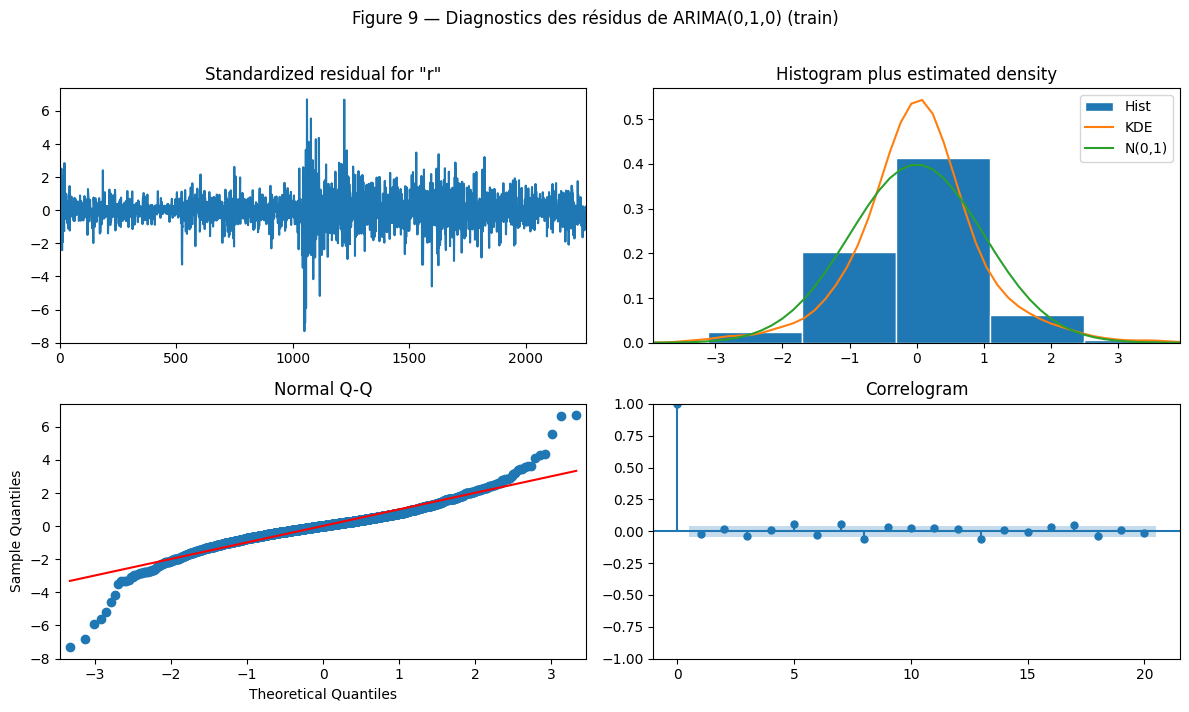

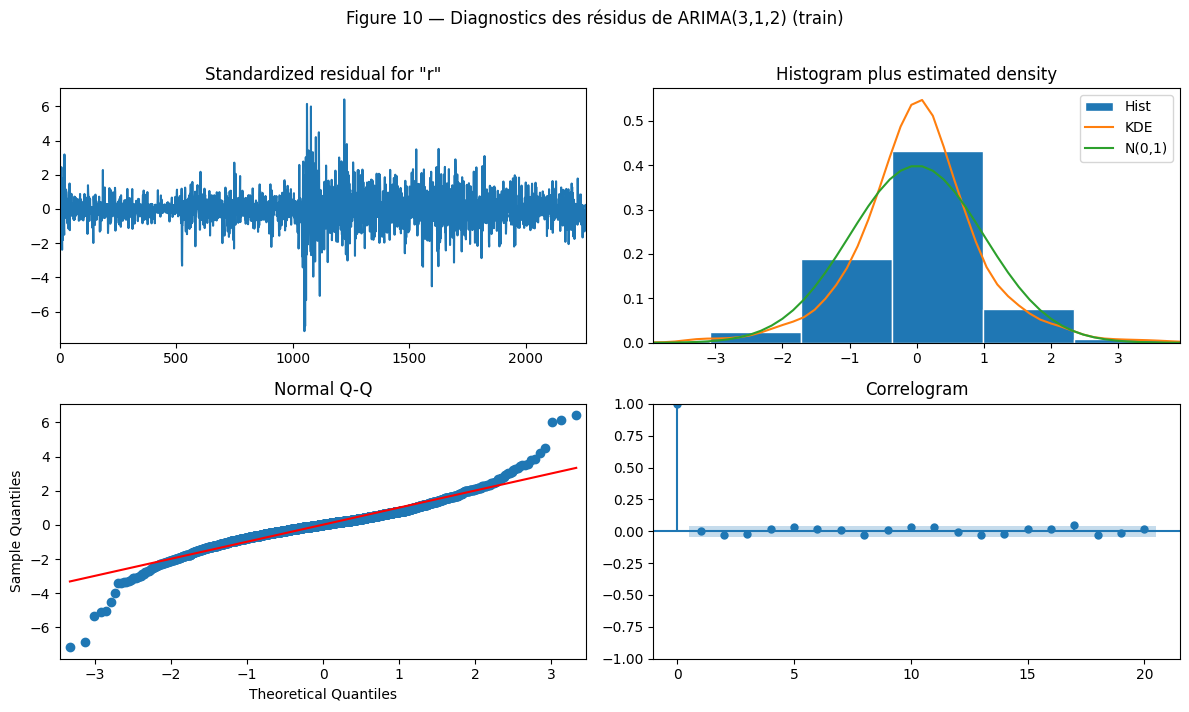

In [41]:
for num, (name, res) in zip((9, 10), retained.items()):
    fig = res.plot_diagnostics(figsize=(12, 7), lags=20)
    fig.suptitle(f"Figure {num} — Diagnostics des résidus de {name} (train)", y=1.01)
    fig.tight_layout()
    save_fig(fig, num, f"diagnostics_{name.replace('(', '').replace(')', '').replace(',', '')}")
    plt.show()

**Interprétation des diagnostics.**

**Autocorrélation des résidus (Ljung-Box).**
- **ARIMA(0,1,0)** : ses résidus sont les rendements eux-mêmes. Le test brut rejette (Q(10) = 34,9, p = 0,0001), mais la version standardisée **ne rejette pas** (p = 0,98 à 10 retards, 0,90 à 20). Comme au §2.3, il n'y a **pas d'autocorrélation dans la moyenne** une fois la volatilité neutralisée.
- **ARIMA(3,1,2)** : malgré ses 5 paramètres, et après correction des degrés de liberté, le test brut rejette encore au seuil de 5 % (p = 0,047 et 0,018). Surtout, la version standardisée **rejette** à 10 retards (p = 0,013), là où la marche aléatoire passe.

Le modèle de l'AIC « nettoie » en apparence le corrélogramme brut (figure 10, plus plat que la figure 9), parce qu'il s'est ajusté aux jours agités de 2020. Mais il **introduit** une structure parasite dans les jours calmes. C'est le symptôme classique d'un sur-ajustement.

**Normalité (Jarque-Bera).** Elle est rejetée pour les deux modèles (JB = 4 142 et 3 376, p < 0,0001 ; excès de kurtosis de 6,6 et 6,0). Sur les graphiques Q-Q, les points s'écartent de la droite aux deux extrémités : les résidus descendent jusqu'à environ −7 écarts-types là où une loi normale s'arrêterait vers −3,3. Il s'agit de **queues épaisses**, surtout à gauche. L'histogramme est plus pointu au centre que la courbe N(0,1).

**Variance conditionnelle (ARCH-LM).** C'est le rejet le plus massif : ARCH-LM(5) = 441 et ARCH-LM(10) = 492 pour la marche aléatoire, et des valeurs comparables pour l'ARIMA(3,1,2), avec p < 0,0001 partout. Sur le graphe des résidus standardisés, les fortes valeurs sont **regroupées** :
- autour de l'observation 1 050, soit le 2020-03-09 ;
- et vers l'observation 1 220, en novembre 2020.

La variance d'un ARIMA est constante par construction : ce modèle ne peut pas représenter ces regroupements.

**Bilan honnête.** Aucun des deux modèles n'a des résidus « bruit blanc gaussien i.i.d. ». Mais leurs échecs sont de nature différente :
- **ARIMA(0,1,0)** décrit correctement la **moyenne** : pas d'autocorrélation résiduelle une fois la volatilité neutralisée. Ce qu'il ne modélise pas, c'est la **variance** (effets ARCH) et la **forme de la loi** (queues épaisses). Ces deux défauts sont exactement ceux que traite un GARCH à loi de Student : ils **justifient la section 3.3**, ils ne disqualifient pas le modèle de moyenne.
- **ARIMA(3,1,2)** ne fait pas mieux sur la variance ni sur la normalité, et fait moins bien sur l'autocorrélation.

**Conséquence pratique.** Les intervalles de prévision gaussiens à variance constante de ces ARIMA seront **trop étroits en période agitée et trop larges en période calme**. On le vérifiera en section 6 en comparant leur couverture à celle des intervalles ARIMA-GARCH.

#### 3.1.5 Décision

| Critère | ARIMA(0,1,0) | ARIMA(3,1,2) | SARIMA s = 5 |
| --- | --- | --- | --- |
| Identification manuelle (ACF/PACF) | ✔ retenu | — | — |
| `auto_arima`, AIC | — | ✔ choisi | — |
| `auto_arima`, BIC | ✔ choisi | — | — |
| Coefficients significatifs (robustes) | aucun à estimer | oui individuellement, mais quasi-annulation des racines | non (p ≥ 0,12) |
| Gain d'AIC robuste (hors 2020, standardisé) | référence | non : il s'inverse | non |
| Résidus sans autocorrélation (LB standardisé) | ✔ p = 0,98 | ✘ p = 0,013 | — |
| Interprétation | prix de demain = prix d'aujourd'hui | cycle de 2,4 jours sans sens économique | effet hebdomadaire inexistant |

**Modèle ARIMA retenu : ARIMA(0,1,0) sans dérive**, c'est-à-dire la **marche aléatoire** : ln P_t = ln P_{t−1} + ε_t, avec σ = √3,184 ≈ 1,78 % par jour.

**Pourquoi ce choix.**
- C'est le choix de l'identification manuelle, du BIC et de tous les contrôles de robustesse.
- Il est cohérent avec l'hypothèse d'**efficience des marchés** : l'information passée sur les prix ne permet pas de prévoir la variation du lendemain.
- La prévision ponctuelle à tout horizon h est simplement le dernier prix observé. C'est pourquoi la marche aléatoire est aussi la **baseline** de la section 6.

**ARIMA(3,1,2) conservé comme modèle concurrent.** C'est le choix de la procédure automatique, et l'écarter sur la seule base de l'échantillon d'apprentissage serait un peu rapide. Il sera donc évalué hors échantillon en section 6, avec le test de Diebold-Mariano. Les diagnostics laissent attendre qu'il ne fasse pas mieux que la marche aléatoire, et il faudra le vérifier plutôt que le supposer.

**Ce qui reste à traiter.**
1. **Effets ARCH massifs** dans les résidus (section 3.3, GARCH).
2. **Queues épaisses** (loi de Student dans le GARCH).
3. **Interactions entre XOM et XLE**, qu'un modèle univarié ignore (section 3.2, VAR et cointégration).

### 3.2 VAR, causalité de Granger et cointégration (train)

**Pourquoi deux niveaux d'analyse.** Le §2.7 a montré que les log-prix de XOM et de XLE sont I(1) et leurs rendements I(0). Chaque outil s'applique donc à la série qui respecte ses hypothèses :
- **Dynamique de court terme : VAR sur les rendements.** Un VAR estimé sur des séries non stationnaires donnerait des tests aux lois non standard, et un risque de régression fallacieuse.
- **Relation de long terme : cointégration sur les log-prix.** La cointégration ne se définit qu'entre séries I(1) : une combinaison linéaire des deux prix peut être stationnaire alors que chaque prix ne l'est pas.

**Si une cointégration existe**, un VAR en différences seul serait mal spécifié, car il oublierait le terme de rappel vers l'équilibre. On estime alors un **VECM**, qui ajoute ce terme au VAR en différences.

On garde la même méthode qu'en 3.1 : chaque résultat est vérifié **hors 2020** et sur **données standardisées par la volatilité passée**, pour distinguer une vraie dynamique d'un effet de l'hétéroscédasticité.

In [42]:
R_pair = TRAIN[["XOM_ret", "XLE_ret"]].dropna()   # rendements en %, 2 261 jours
L_pair = TRAIN[["XOM_logp", "XLE_logp"]]          # log-prix, 2 262 jours
print(f"Corrélation des rendements XOM/XLE (train) : {R_pair.corr().iloc[0, 1]:.3f}")

Corrélation des rendements XOM/XLE (train) : 0.915


#### 3.2.1 Choix de l'ordre du VAR

Quatre critères d'information sont comparés pour un ordre maximal de 10 retards, soit deux semaines de bourse :
- l'**AIC** et le **FPE**, orientés vers la prévision ;
- le **BIC** et le **HQ**, convergents, qui pénalisent davantage les paramètres.

Chaque retard ajoute K² = 4 coefficients.

In [43]:
ic = C.var_ic_table(R_pair)
order_sel = C.var_order_selection(R_pair)
save_table(ic, "tab17_var_criteres")
save_table(order_sel, "tab17b_var_ordre_robustesse")
display(ic.round(4))
order_sel

,AIC,BIC,HQIC,FPE
ordre p,,,,
0,0.6307,0.6358,0.6326,1.8790
1,0.6305,0.6457,0.6360,1.8785
2,0.6211,0.6465,0.6304,1.8610
3,0.6184,0.6540,0.6314,1.8560
4,0.6180,0.6637,0.6347,1.8552
5,0.6173,0.6732,0.6377,1.8539
6,0.6159,0.6820,0.6400,1.8514
7,0.5949,0.6712,0.6228,1.8129
8,0.5951,0.6815,0.6266,1.8132


,AIC,BIC,HQIC,FPE
échantillon complet,9,0,7,9
hors 2020,0,0,0,0
standardisé (vol. 21 j passée),0,0,0,0


**Interprétation du choix d'ordre.**

**Les critères divergent fortement :**

| Critère | Ordre choisi |
| --- | --- |
| AIC | 9 |
| FPE | 9 |
| HQ | 7 |
| BIC | **0** |

Le BIC ne retient aucun retard : pour lui, les rendements de XOM et de XLE n'ont aucune dynamique commune exploitable. La valeur de l'AIC est presque plate de p = 0 à p = 6 (de 0,631 à 0,616), puis **chute d'un coup au retard 7** (0,595). Tout le gain de l'AIC tient donc à ce seul retard. C'est exactement le retard où l'EDA avait trouvé la plus forte autocorrélation de XLE (0,129, §2.3), et elle venait de 2020.

**Le contrôle de robustesse tranche :** hors 2020, comme sur rendements standardisés, **les quatre critères choisissent p = 0**. Les ordres 7 et 9 ne reflètent donc pas une dynamique de la moyenne, mais l'hétéroscédasticité de mars 2020.

**Décision.** Le modèle multivarié le plus fidèle aux données est un **VAR(0)** : un bruit blanc bivarié dont les chocs sont fortement corrélés (corrélation de 0,915), sans aucune dépendance au passé. Un VAR(0) ne permet toutefois aucun test de Granger, puisqu'il n'a pas de retard. On estime donc aussi le **VAR(1)**, le plus petit VAR qui en contienne, ainsi que les VAR(7) et VAR(9) des critères, pour comparer leurs diagnostics.

#### 3.2.2 Estimation et diagnostics du VAR

On estime les VAR désignés par les critères, pour les comparer :
- **VAR(0)** : le choix du BIC et de toutes les versions robustes ;
- **VAR(1)** : le plus petit VAR qui contienne des retards, donc le minimum pour tester une causalité de Granger ;
- **VAR(7)** et **VAR(9)** : les choix du HQ et de l'AIC.

**Diagnostics appliqués à chacun :**
- **stabilité** : module des valeurs propres de la matrice compagnon < 1 ;
- **autocorrélation** : Portmanteau multivarié de Hosking, ajusté, sur résidus bruts puis standardisés ;
- **normalité** : Jarque-Bera multivarié ;
- **effets ARCH** : ARCH-LM équation par équation.

In [44]:
var_fits = {f"VAR({p})": C.fit_var(R_pair, p) for p in (0, 1, 7, 9)}
var_diag = pd.DataFrame([C.var_diagnostics(r, n) for n, r in var_fits.items()]).set_index("modèle")
save_table(var_diag, "tab18_var_diagnostics")
var_diag.round(4).T

modèle,VAR(0),VAR(1),VAR(7),VAR(9)
stable,True,True,True,True
module max (matrice compagnon),0.0000,0.0411,0.8054,0.8054
p Portmanteau(10),0.0000,0.0000,0.0246,0.2415
p Portmanteau(20),0.0000,0.0000,0.0001,0.0003
p Portmanteau(10) standardisé,0.7678,0.0376,0.0000,0.0000
p Portmanteau(20) standardisé,0.4476,0.0334,0.0000,0.0000
JB multivarié,33989.3561,34565.0860,22674.3715,21681.4313
p JB,0.0000,0.0000,0.0000,0.0000
ARCH-LM(5) XOM_ret,443.0082,423.9853,328.2938,321.5098
p ARCH-LM(5) XOM_ret,0.0000,0.0000,0.0000,0.0000


In [45]:
# Coefficients du VAR(1) : estimation complète puis hors 2020, pour juger de leur stabilité.
v1_full = var_fits["VAR(1)"]
v1_ex2020 = C.fit_var(R_pair[R_pair.index.year != 2020], 1)
coefs = pd.concat({"complet": v1_full.params, "p-value (classique)": v1_full.pvalues,
                   "hors 2020": v1_ex2020.params}, axis=1)
save_table(coefs, "tab18b_var1_coefficients")
coefs.round(4)

complet         p-value (classique)         hors 2020        
           XOM_ret XLE_ret             XOM_ret XLE_ret   XOM_ret XLE_ret
const       0.0323  0.0322              0.3896  0.4251    0.0564  0.0546
L1.XOM_ret  0.1010  0.1046              0.0529  0.0626    0.0330 -0.0084
L1.XLE_ret -0.1268 -0.1344              0.0089  0.0100   -0.0082  0.0159

**Interprétation des diagnostics du VAR.**

**Stabilité.** Les quatre VAR sont stables. Les valeurs propres de la matrice compagnon ont un module d'au plus 0,04 pour le VAR(1) et 0,81 pour les VAR(7) et VAR(9), toutes inférieures à 1 : les prévisions convergent vers la moyenne et les réponses aux chocs s'amortissent.

**Autocorrélation des résidus (Portmanteau).** C'est le diagnostic qui départage les modèles :

| Modèle | p brut (h = 10) | p standardisé (h = 10) | p standardisé (h = 20) |
| --- | --- | --- | --- |
| VAR(0) | < 0,0001 | **0,77** | **0,45** |
| VAR(1) | < 0,0001 | 0,038 | 0,033 |
| VAR(7) | 0,025 | < 0,0001 | < 0,0001 |
| VAR(9) | 0,24 | < 0,0001 | < 0,0001 |

- **Résidus bruts.** Ajouter des retards fait disparaître une partie de l'autocorrélation : le VAR(9) passe même à h = 10. Mais ce « nettoyage » porte sur les jours agités de 2020.
- **Résidus standardisés.** Le classement s'inverse. Seul le **VAR(0) est propre** ; plus on ajoute de retards, plus on crée de structure parasite dans les périodes calmes. C'est la même signature de sur-ajustement que pour l'ARIMA(3,1,2) en 3.1.

**Coefficients du VAR(1) : l'origine du problème.**
- **Sur l'échantillon complet**, chaque rendement réagit **positivement** au rendement passé de XOM (+0,10) et **négativement** à celui de XLE (−0,13). Seul ce dernier est significatif en test classique (p ≈ 0,01).
- **Hors 2020**, ces coefficients s'effondrent : +0,03 et −0,01 dans l'équation de XOM, −0,01 et +0,02 dans celle de XLE.

La dynamique estimée vient presque entièrement des journées de mars 2020. Avec des régresseurs aussi corrélés (0,915), deux coefficients opposés reviennent d'ailleurs à un effet de l'**écart** de la veille entre XOM et XLE.

**Normalité et effets ARCH.**
- La normalité est massivement rejetée : Jarque-Bera multivarié entre 21 681 et 34 565.
- Les effets ARCH le sont aussi : ARCH-LM(5) entre 321 et 458 selon le modèle et l'équation, avec p < 0,0001 partout.

Comme en 3.1, ces deux défauts concernent la variance et la forme de la loi, et relèvent d'un modèle GARCH (§3.3). La corrélation entre les résidus des deux équations (≈ 0,915) montre que l'essentiel du lien entre XOM et XLE est **contemporain** : les deux actifs bougent le même jour, pas l'un après l'autre.

#### 3.2.3 Causalité de Granger

**Définition.** « X cause Y au sens de Granger » signifie que les valeurs passées de X **améliorent la prévision** de Y, une fois connues les valeurs passées de Y. Il s'agit d'une **prédictibilité incrémentale**, pas d'une causalité économique : deux séries peuvent se « causer » au sens de Granger simplement parce qu'elles réagissent avec des délais différents à une même information.

**Test.** Pour chaque équation, on teste H₀ : tous les coefficients des retards de l'autre variable sont nuls, en trois versions :
- **F classique** : le test standard du VAR, qui suppose des erreurs homoscédastiques ;
- **Wald robuste HC3** : corrige l'hétéroscédasticité ;
- **Wald HAC** (Newey-West, 7 retards) : corrige aussi l'autocorrélation.

Le test est fait pour p = 1, 7 et 9, sur l'échantillon complet puis hors 2020.

In [46]:
granger = C.granger_tests(R_pair)
save_table(granger, "tab19_granger")
granger.round(4)

p classique  p HC3  p HAC
échantillon         retards p sens                                        
échantillon complet 1         XLE_ret → XOM_ret       0.0089 0.1954 0.0908
                              XOM_ret → XLE_ret       0.0627 0.4210 0.2069
                    7         XLE_ret → XOM_ret       0.0000 0.0339 0.0085
                              XOM_ret → XLE_ret       0.0028 0.5151 0.0170
                    9         XLE_ret → XOM_ret       0.0000 0.0162 0.0016
                              XOM_ret → XLE_ret       0.0056 0.6351 0.0427
hors 2020           1         XLE_ret → XOM_ret       0.8708 0.8894 0.8812
                              XOM_ret → XLE_ret       0.8732 0.8929 0.8861
                    7         XLE_ret → XOM_ret       0.0549 0.0893 0.1174
                              XOM_ret → XLE_ret       0.0257 0.0551 0.0471
                    9         XLE_ret → XOM_ret       0.0916 0.1791 0.1870
                              XOM_ret → XLE_ret       0.0466 0.1024 0.1208

**Interprétation des tests de Granger.**

**La conclusion dépend entièrement de l'inférence utilisée et de l'échantillon :**

| Retards | Sens | F classique | HC3 robuste | HAC | HC3 hors 2020 |
| --- | --- | --- | --- | --- | --- |
| 1 | XLE → XOM | **0,009** | 0,195 | 0,091 | 0,889 |
| 1 | XOM → XLE | 0,063 | 0,421 | 0,207 | 0,893 |
| 7 | XLE → XOM | **< 0,001** | **0,034** | **0,009** | 0,089 |
| 7 | XOM → XLE | **0,003** | 0,515 | **0,017** | 0,055 |
| 9 | XLE → XOM | **< 0,001** | **0,016** | **0,002** | 0,179 |
| 9 | XOM → XLE | **0,006** | 0,635 | **0,043** | 0,102 |

(En gras : rejet de H₀ au seuil de 5 %.)

**Lecture.**
1. **Le test F classique** trouve une causalité partout ou presque. Mais il suppose une variance constante, ce que les tests ARCH-LM réfutent, et il rejette donc trop souvent.
2. **Avec une erreur-type robuste** (HC3), la causalité disparaît à 1 retard. À 7 et 9 retards, il ne reste que le sens **XLE → XOM**.
3. **Hors 2020**, plus aucun test robuste ne rejette au seuil de 5 %. Avec 7 retards, quelques p-values restent proches du seuil (0,055 en HC3 pour XOM → XLE, 0,047 en HAC), mais sans régularité d'un réglage à l'autre.

**Conclusion.** Il n'y a **pas de prédictibilité croisée robuste** entre les rendements de XOM et de XLE. Le seul signal, le passé de XLE aidant à prévoir XOM, n'apparaît qu'avec 7 à 9 retards, sur l'échantillon qui contient 2020. Il disparaît sans cette année.

**Interprétation prudente.** Même là où il est significatif, ce résultat signifierait seulement que « le passé de XLE aide à prévoir XOM », **pas** que « XLE cause XOM ». Les deux actifs réagissent à la même information sectorielle (prix du pétrole, demande), et un décalage d'un jour peut venir de différences de liquidité ou d'heure de cotation sans lien causal.

L'absence de prédictibilité croisée est cohérente avec l'**efficience des marchés** : si le passé de l'ETF permettait de prévoir l'action, cette information serait exploitée et disparaîtrait des prix.

#### 3.2.4 Cointégration des log-prix

**Engle-Granger (deux étapes).** On régresse un log-prix sur l'autre, puis on teste la racine unitaire du résidu. H₀ : pas de cointégration. Les valeurs critiques de MacKinnon sont plus sévères que celles d'un ADF simple, puisque le résidu est estimé. Le test est fait dans les deux sens, car il n'est pas symétrique, avec une constante puis avec une constante et une tendance.

**Johansen.** Il teste directement le **rang** r de cointégration dans un VAR en niveaux, avec deux statistiques :
- la **trace**, qui teste H₀ : r ≤ r₀ ;
- la **valeur propre maximale**, qui teste H₀ : r = r₀ contre r = r₀ + 1.

On lit les tests de façon séquentielle : d'abord r = 0, puis r ≤ 1 si le premier est rejeté.

Le nombre de retards en différences k dépend du choix d'ordre fait en 3.2.1. On présente donc les trois valeurs possibles : k = 0 (VAR(1) en niveaux, choix du BIC et des versions robustes), k = 6 (HQ) et k = 8 (AIC).

In [47]:
eg = C.engle_granger(L_pair)
save_table(eg, "tab20_engle_granger")
eg.round(4)

statistique  valeur critique 5 %  p-value  H0 rejetée (5 %)
régression            déterministe                                                                     
XOM_logp sur XLE_logp constante                 -3.4565              -3.3388   0.0365              True
                      constante + tendance      -3.4753              -3.7848   0.1050             False
XLE_logp sur XOM_logp constante                 -3.6092              -3.3388   0.0239              True
                      constante + tendance      -3.6374              -3.7848   0.0719             False

In [48]:
joh = C.johansen_table(L_pair, {"k = 0 (BIC, robuste)": 0, "k = 6 (HQ)": 6, "k = 8 (AIC)": 8})
save_table(joh, "tab21_johansen")
joh.round(2)

trace  VC trace 10 %  VC trace 5 %    λmax  VC λmax 10 %  VC λmax 5 %        trace : décision λmax : décision
retards (Δ)          H0                                                                                                                   
k = 0 (BIC, robuste) r = 0 14.7300        13.4300       15.4900 12.1900       12.3000      14.2600  rejet à 10 % seulement       non rejet
                     r ≤ 1  2.5300         2.7100        3.8400  2.5300        2.7100       3.8400               non rejet       non rejet
k = 6 (HQ)           r = 0 15.8000        13.4300       15.4900 15.1300       12.3000      14.2600             rejet à 5 %     rejet à 5 %
                     r ≤ 1  0.6700         2.7100        3.8400  0.6700        2.7100       3.8400               non rejet       non rejet
k = 8 (AIC)          r = 0 21.6300        13.4300       15.4900 21.1400       12.3000      14.2600             rejet à 5 %     rejet à 5 %
                     r ≤ 1  0.4900         2.7100        3.8400  0.4900        2.7100       3.8400               non rejet       non rejet

In [49]:
# Stabilité de la relation : est-elle présente dans chaque moitié du train, de part et d'autre de 2020 ?
subp = C.cointegration_subperiods(L_pair, {"2016-2019": ("2016", "2019"), "2021-2024": ("2021", "2024"),
                                           "2016-2024 (train complet)": ("2016", "2024")})
save_table(subp, "tab22_cointegration_sous_periodes")
subp.round(3)

,n,Engle-Granger p-value,Johansen trace (r = 0),VC 10 %,VC 5 %
période,,,,,
2016-2019,1006,0.0810,14.3320,13.4290,15.4940
2021-2024,1003,0.2320,10.5540,13.4290,15.4940
2016-2024 (train complet),2262,0.0360,14.7260,13.4290,15.4940


**Interprétation des tests de cointégration.** Les résultats sont **ambigus** et sont rapportés comme tels.

**Engle-Granger.**
- **Avec constante**, l'absence de cointégration est rejetée au seuil de 5 % dans les deux sens : statistique −3,46, p = 0,037 (XOM sur XLE) ; −3,61, p = 0,024 (XLE sur XOM). La valeur critique est −3,34.
- **Avec une tendance en plus**, elle ne l'est plus : p = 0,105 et 0,072.

La tendance n'est de toute façon pas justifiée, puisque la dérive des rendements n'est pas significative (§2.2). La spécification « constante » est la plus pertinente.

**Johansen.** Le verdict dépend du nombre de retards :

| Retards en différences | Trace (r = 0) | λmax (r = 0) | Décision |
| --- | --- | --- | --- |
| k = 0 (BIC, robuste) | 14,73 | 12,19 | trace : rejet à 10 % seulement (VC à 5 % : 15,49) ; λmax : non rejet |
| k = 6 (HQ) | 15,80 | 15,13 | rejet à 5 % |
| k = 8 (AIC) | 21,63 | 21,14 | rejet à 5 % |

Dans les trois cas, r ≤ 1 n'est pas rejeté. S'il y a cointégration, il y a donc **au plus une** relation.

Or les retards 6 et 8 sont précisément ceux que les contrôles de robustesse ont attribués à 2020 (§3.2.1). Avec l'ordre robuste (k = 0), Johansen ne rejette qu'au seuil de **10 %**.

**Sous-périodes.** La relation n'est **significative dans aucune moitié** du train prise séparément :
- 2016–2019 : Engle-Granger p = 0,081, trace 14,33 ;
- 2021–2024 : Engle-Granger p = 0,232, trace 10,55.

On ne peut toutefois pas en conclure qu'elle est absente. Avec quatre ans de données chacune, ces sous-périodes offrent moins de puissance pour détecter un retour lent à l'équilibre.

**Verdict.** La cointégration XOM/XLE est **faible et fragile**. Elle est significative à 5 % avec Engle-Granger (spécification avec constante), mais seulement à 10 % avec Johansen sous l'ordre robuste, et elle n'est stable dans aucune des deux sous-périodes. Le retour à l'équilibre est donc, au mieux, lent et imparfait.

**Un lien en partie mécanique.** XOM est le **premier composant** de l'ETF XLE : **24,47 %** de l'ETF au 5 novembre 2026, devant Chevron (18,78 %) ([StockAnalysis, positions de XLE](https://stockanalysis.com/etf/xle/holdings/)). D'autres relevés de 2026 donnent 22 à 23 %. Cette pondération varie dans le temps, et sa valeur exacte sur 2016–2024 n'est pas vérifiée ici. Avec environ un quart de l'ETF, une partie de la relation entre les deux prix tient en tout cas à la construction même de l'indice. Les écarts, eux, viennent de tout ce qui distingue XOM du reste du secteur : résultats propres à l'entreprise, rachats d'actions, différence d'exposition au raffinage.

**Décision.** Le cahier demande un VECM si une cointégration est détectée. On estime donc un VECM avec **r = 1**, retenu au seuil de 10 %, et on l'interprète **conditionnellement** : il décrit le retour à l'équilibre *si* la relation existe.

#### 3.2.5 VECM

**Spécification.**
- **Rang** r = 1, avec k = 0 retard en différences (cohérent avec l'ordre robuste du VAR).
- **Constante restreinte** à la relation de cointégration (« ci ») : la dérive n'est pas significative (§2.2, §3.1), il n'y a donc pas de tendance linéaire dans les niveaux.

**Forme du modèle.**

  Δy_t = α (β′y_{t−1} + c) + ε_t,  avec y_t = (ln XOM_t, ln XLE_t)′

- **β** est la relation d'équilibre de long terme, normalisée sur XOM.
- **z_t = β′y_t + c** est l'écart à cet équilibre.
- **α** mesure la réaction de chaque actif à cet écart.

**Demi-vie.** L'écart évolue selon z_t = (1 + β′α) z_{t−1} + bruit. Sa demi-vie vaut donc **ln(0,5) / ln(1 + β′α)**. C'est la généralisation à deux variables de la formule ln(0,5)/ln(1 + α) du plan, qui suppose qu'un seul actif s'ajuste. On la recoupe avec la demi-vie d'un AR(1) estimé directement sur l'écart.

In [50]:
vecm = C.fit_vecm(L_pair, k_ar_diff=0, rank=1)
vecm_tab = C.vecm_summary(vecm, ["XOM", "XLE"])
save_table(vecm_tab, "tab23_vecm")
display(vecm_tab.round(5))

beta = vecm.beta.ravel()
spread = pd.Series(L_pair.to_numpy() @ beta + vecm.const_coint.ravel()[0], index=L_pair.index, name="écart")
hl = C.spread_half_life(spread)
print(f"Contrôle : AR(1) de l'écart, ρ = {hl['rho']:.4f}, demi-vie = {hl['demi-vie (jours)']:.1f} jours de bourse")
print(f"Écart : moyenne = {spread.mean():.4f}, écart-type = {spread.std():.4f}, "
      f"min = {spread.min():.3f} le {spread.idxmin().date()}, max = {spread.max():.3f} le {spread.idxmax().date()}")

,valeur,p-value
paramètre,,
β (XOM),1.0000,NaN
β (XLE),-1.1282,NaN
constante de la relation,-0.4531,NaN
α (XOM),-0.0006,0.9279
α (XLE),0.0093,0.1594
vitesse de l'écart β'α,-0.0110,NaN
demi-vie de l'écart (jours de bourse),62.5794,NaN


Contrôle : AR(1) de l'écart, ρ = 0.9890, demi-vie = 62.6 jours de bourse
Écart : moyenne = -0.0003, écart-type = 0.0613, min = -0.150 le 2018-05-04, max = 0.268 le 2020-03-18


In [51]:
vecm_diag = pd.DataFrame([C.vecm_diagnostics(vecm, "VECM (r = 1, k = 0)")]).set_index("modèle")
save_table(vecm_diag, "tab24_vecm_diagnostics")
vecm_diag.round(4).T

modèle,"VECM (r = 1, k = 0)"
p Portmanteau(10),0.0000
p Portmanteau(20),0.0000
p Portmanteau(10) standardisé,0.5310
p Portmanteau(20) standardisé,0.3551
JB multivarié,34529.3069
p JB,0.0000
p ARCH-LM(5) éq. 1,0.0000
p ARCH-LM(5) éq. 2,0.0000


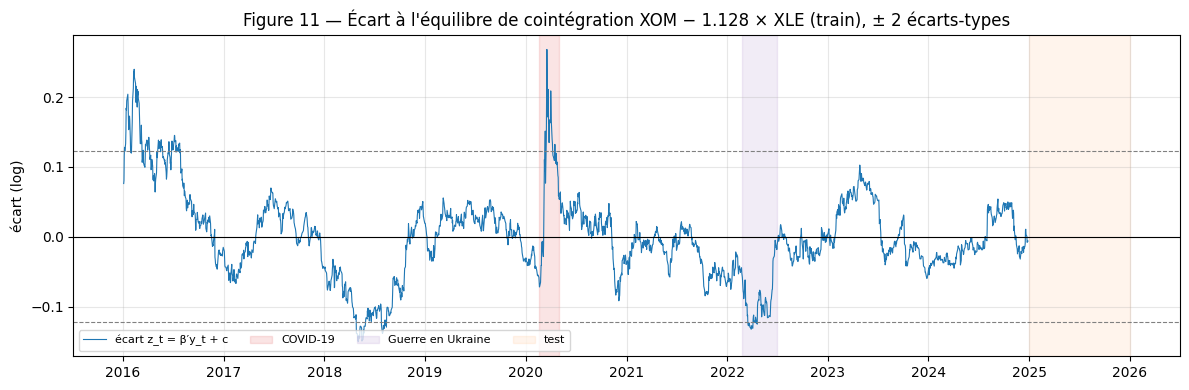

In [52]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spread.index, spread, lw=0.8, color="tab:blue", label="écart z_t = β′y_t + c")
m, s = spread.mean(), spread.std()
ax.axhline(m, color="black", lw=0.8)
for k in (-2, 2):
    ax.axhline(m + k * s, color="grey", ls="--", lw=0.8)
shade(ax, legend=True)
ax.set_ylabel("écart (log)")
ax.set_title(f"Figure 11 — Écart à l'équilibre de cointégration XOM − {-beta[1]:.3f} × XLE (train), ± 2 écarts-types")
ax.legend(loc="lower left", fontsize=8, ncol=4)
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 11, "ecart_cointegration")
plt.show()

**Interprétation du VECM.**

**Relation de long terme (β).** L'équilibre s'écrit

  ln XOM ≈ 1,128 × ln XLE − 0,453.

À long terme, une hausse de 1 % de XLE va de pair avec une hausse d'environ 1,13 % de XOM. XOM est donc un peu plus sensible que la moyenne de son secteur, ce qui est un ordre de grandeur plausible pour une major pétrolière.

**L'écart à l'équilibre (figure 11).** Il oscille autour de zéro (moyenne −0,0003, écart-type 0,061), mais par **longues excursions** de plusieurs mois :
- début 2016 : environ +0,24, la série partant loin de l'équilibre ;
- mi-2018 : creux de −0,15 le 2018-05-04 ;
- **18 mars 2020** : pic de **+0,27**. Ce jour-là, XLE a perdu nettement plus que XOM (−15,5 % contre −10,6 %) ;
- début 2022 : creux d'environ −0,13.

Un écart de 0,1 en log correspond à environ 10 % de sur- ou sous-valorisation relative.

**Vitesse d'ajustement (α).**
- α(XOM) = −0,0006 (p = 0,93) : XOM **ne s'ajuste pas** à l'écart.
- α(XLE) = +0,0093 (p = 0,16) : si l'ajustement existe, il passe plutôt par **XLE**. Quand XOM est cher relativement au secteur (écart positif), c'est XLE qui monte pour combler l'écart. Ce coefficient **n'est pas significatif** au seuil de 5 %.

Aucun des deux α n'est significatif, ce qui est cohérent avec la faiblesse de la cointégration en 3.2.4 : la force de rappel existe peut-être, mais elle est trop faible pour être mesurée avec précision.

**Demi-vie.** La vitesse de retour de l'écart vaut β′α = −0,0110. Elle donne une **demi-vie de 62,6 jours de bourse**, soit environ trois mois : il faut ~3 mois pour résorber la moitié d'un écart. Un AR(1) estimé directement sur l'écart donne la même valeur (ρ = 0,989, 62,6 jours), ce qui confirme le calcul.

**Pourquoi β′α et pas un α seul.** La formule du plan, ln(0,5)/ln(1 + α), ne s'applique que si un seul actif s'ajuste. Appliquée à α(XOM) = −0,0006, elle donnerait plus de 1 200 jours ; appliquée à α(XLE), positif, elle n'a pas de sens. Quand les deux actifs bougent, c'est la combinaison β′α qui mesure la vitesse de l'écart.

**Diagnostics du VECM.**
- **Autocorrélation.** Le Portmanteau brut rejette, mais la version standardisée **ne rejette pas** (p = 0,53 à h = 10, 0,36 à h = 20) : le VECM ne laisse pas d'autocorrélation dans la moyenne. Contrairement au VAR(1), il ne crée pas de structure parasite.
- **Normalité et effets ARCH** : massivement rejetés, comme pour tous les modèles précédents (Jarque-Bera = 34 529 ; ARCH-LM p < 0,0001).

**Portée pratique.** Une demi-vie de trois mois est longue face à l'horizon de prévision du projet (h = 10 jours) : en 10 jours, le rappel ne corrige qu'environ 1 − 0,989¹⁰ ≈ 10 % d'un écart. On ne doit donc pas attendre du VECM un gain de prévision notable à court terme sur la marche aléatoire, ce que la section 6 vérifiera.

#### 3.2.6 Décision

| Question | Réponse | Preuve principale |
| --- | --- | --- |
| Dynamique de court terme entre les rendements ? | **Non** : VAR(0) | tous les critères choisissent p = 0 hors 2020 et sur rendements standardisés ; seul VAR(0) passe le Portmanteau standardisé (p = 0,77) |
| Lien entre XOM et XLE ? | **Oui, mais contemporain** | corrélation des chocs de 0,915 le même jour |
| Causalité de Granger ? | **Pas de prédictibilité croisée robuste** | rejet seulement en F classique ; robuste hors 2020 : aucun rejet à 5 % |
| Cointégration des log-prix ? | **Faible et fragile** | Engle-Granger p = 0,037 ; Johansen (ordre robuste) au seuil de 10 % seulement ; non significative par sous-période |
| Retour à l'équilibre ? | **Lent et imprécis** | demi-vie de 62,6 jours ; aucun α significatif |

**Modèles conservés pour la section 6 (prévision).**
- **VAR(1)** sur les rendements, comme représentant du VAR. C'est le plus petit VAR à retards, mais ses coefficients sont tirés par 2020 : il servira de point de comparaison.
- **VECM** (r = 1, k = 0), comme modèle de cointégration. Évalué hors échantillon, il dira si le faible rappel vers l'équilibre apporte quelque chose à 10 jours.
- La **marche aléatoire** reste la référence. Elle équivaut d'ailleurs au VAR(0) sans constante.

**Limites à garder en tête.**
1. Tous les tests multivariés de cette section supposent une variance constante. L'hétéroscédasticité massive peut fausser le niveau réel des tests de Johansen, d'où la prudence sur le verdict de cointégration.
2. Le lien entre XOM et XLE est en partie **mécanique**, XOM pesant environ un quart de l'ETF (24,47 % en novembre 2026).
3. Les résidus de tous les modèles gardent des effets ARCH et des queues épaisses, ce qui justifie la section 3.3.

### 3.3 Volatilité conditionnelle : ARCH et GARCH (rendements de XOM, train)

**Pourquoi cette section.** Tous les modèles précédents (ARIMA, VAR, VECM) laissent des résidus à effets ARCH massifs (§3.1.4, §3.2.2). Leur variance est constante par construction, alors que celle des rendements ne l'est manifestement pas. Le GARCH modélise justement la **variance conditionnelle** σ²_t, c'est-à-dire l'amplitude attendue du rendement de demain sachant le passé.

**Modèle complet.** On garde pour la moyenne le choix du §3.1, la marche aléatoire sans dérive :

  r_t = ε_t,  ε_t = σ_t z_t,  z_t i.i.d. de variance 1

  σ²_t = ω + α ε²_{t−1} + γ ε²_{t−1} 1[ε_{t−1} < 0] + β σ²_{t−1}

- **ω** est la constante de la variance.
- **α** mesure l'effet du choc d'hier (« ARCH »).
- **β** mesure l'inertie de la variance (« GARCH »).
- **γ**, seulement dans le GJR-GARCH, est un supplément de réaction aux **baisses** : c'est l'effet de levier.

**Convention de notation.** Elle suit la bibliothèque `arch` : GARCH(p, q) a p termes α et q termes β. Ainsi, GARCH(1,2) a un terme α et deux termes β.

**Piège à retenir.** Un GARCH ne prévoit **pas le sens** du prix, seulement l'**amplitude** probable de ses variations.

In [53]:
# Point de départ exigé par le plan : effets ARCH dans les résidus du modèle de moyenne retenu (ARIMA(0,1,0)).
from statsmodels.stats.diagnostic import het_arch

r_xom = TRAIN["XOM_ret"].dropna()
resid_rw = r_train.to_numpy()   # résidus de la marche aléatoire sans dérive = rendements
arch_start = pd.DataFrame({f"ARCH-LM({k})": dict(zip(["statistique", "p-value"], het_arch(resid_rw, nlags=k)[:2]))
                           for k in (5, 10)}).T
arch_start

,statistique,p-value
ARCH-LM(5),441.1677,0.0000
ARCH-LM(10),491.5506,0.0000


**Interprétation du test ARCH-LM de départ.** Le test régresse les résidus au carré ε²_t sur leurs propres retards, sous H₀ : « pas d'effet ARCH, variance conditionnelle constante ». Sur les résidus de la marche aléatoire, il donne ARCH-LM(5) = 441,2 et ARCH-LM(10) = 491,6, avec p < 0,0001 : **H₀ est massivement rejetée**.

Les gros chocs d'hier annoncent donc de gros chocs aujourd'hui, ce qui confirme l'ACF des rendements au carré (figure 5, §2.3). La modélisation de la variance conditionnelle n'est pas une option : c'est la principale structure exploitable de cette série.

#### 3.3.1 Comparaison des spécifications

On compare **quatre structures**, chacune estimée avec **trois lois** pour z_t :

| Structure | Rôle | Loi | Rôle |
| --- | --- | --- | --- |
| GARCH(1,1) | référence | normale | référence |
| GARCH(1,2) et GARCH(2,1) | ordres supérieurs demandés par le plan | Student | queues épaisses (§2.2) |
| GJR(1,1) | effet de levier | Student asymétrique | asymétrie en plus |

Pour chaque modèle, on vérifie que les contraintes qui garantissent une variance positive sont respectées (ω > 0 ; α, γ, β ≥ 0) et que la persistance est inférieure à 1.

In [54]:
garch_specs = {"GARCH(1,1)": dict(p=1, q=1), "GARCH(1,2)": dict(p=1, q=2),
               "GARCH(2,1)": dict(p=2, q=1), "GJR(1,1)": dict(p=1, o=1, q=1)}
garch_tab = C.garch_compare(r_xom, garch_specs)
save_table(garch_tab, "tab25_garch_comparaison")
garch_tab.round(3)

,,nb paramètres,log-vraisemblance,AIC,BIC,ΔAIC,"ω > 0 et α, γ, β ≥ 0",ΔBIC,persistance,persistance < 1,demi-vie (jours),converge
modèle,loi,,,,,,,,,,,
"GJR(1,1)",t,5,-4041.1670,8092.3340,8120.9520,0.4140,True,0.0000,0.9990,True,1015.3590,True
"GARCH(1,1)",t,4,-4045.2560,8098.5130,8121.4070,6.5930,True,0.4550,0.9990,True,690.6800,True
"GJR(1,1)",skewt,6,-4039.9600,8091.9200,8126.2610,0.0000,True,5.3100,0.9990,True,1225.3670,True
"GARCH(1,1)",skewt,5,-4043.9840,8097.9690,8126.5860,6.0490,True,5.6350,0.9990,True,820.0450,True
"GARCH(1,2)",t,5,-4044.2900,8098.5790,8127.1970,6.6590,True,6.2460,0.9990,True,655.4780,True
"GARCH(2,1)",t,5,-4045.2560,8100.5130,8129.1300,8.5930,True,8.1790,0.9990,True,690.7210,True
"GARCH(1,2)",skewt,6,-4043.2110,8098.4220,8132.7630,6.5020,True,11.8120,0.9990,True,783.1140,True
"GARCH(2,1)",skewt,6,-4043.9840,8099.9690,8134.3100,8.0490,True,13.3580,0.9990,True,819.6520,True
"GJR(1,1)",normal,4,-4078.3610,8164.7210,8187.6150,72.8010,True,66.6640,0.9980,True,300.6970,True


In [55]:
# Faut-il une moyenne non nulle ? On compare au modèle avec constante (même structure et même loi).
mu_test = C.fit_garch(r_xom, p=1, o=1, q=1, dist="t", mean="Constant")
print(f"GJR(1,1)-t avec constante : μ = {mu_test.params['mu']:.4f} (p = {mu_test.pvalues['mu']:.3f}), "
      f"BIC = {mu_test.bic:.2f} contre {garch_tab.loc[('GJR(1,1)', 't'), 'BIC']:.2f} sans constante")

GJR(1,1)-t avec constante : μ = 0.0272 (p = 0.270), BIC = 8127.47 contre 8120.95 sans constante


**Interprétation de la comparaison des spécifications.**

1. **La loi de Student s'impose nettement.** Pour le GARCH(1,1), passer de la loi normale à la loi de Student améliore la log-vraisemblance de 37,5 points (−4 082,8 → −4 045,3) pour un seul paramètre en plus, ν. Le BIC baisse de 67 points. C'est cohérent avec les queues épaisses du §2.2 : même après avoir modélisé la variance, les chocs extrêmes restent plus fréquents que sous une loi normale.

2. **La loi de Student asymétrique n'apporte rien.** Elle gagne au plus 1,3 point de vraisemblance, et son BIC est plus mauvais de plus de 5 points. L'asymétrie modérée des rendements (skewness de −0,16, §2.2) ne justifie pas ce paramètre en plus.

3. **Les ordres supérieurs n'apportent rien non plus.**
   - Le GARCH(2,1) a exactement la même vraisemblance que le GARCH(1,1) : le second terme α est estimé à zéro.
   - Le GARCH(1,2) gagne moins d'un point de vraisemblance, avec un BIC plus mauvais de 5,8 points.

4. **L'effet de levier est réel.** Le GJR(1,1) de Student améliore la vraisemblance de 4,1 points par rapport au GARCH(1,1) de Student. Le test du rapport de vraisemblance vaut LR = 8,2 (1 ddl, p ≈ 0,004), et le coefficient γ est significatif en robuste (p = 0,004, voir ci-dessous). L'AIC le préfère nettement (−6,2). Le BIC le place aussi en tête, mais de justesse (−0,5), puisque sa pénalité absorbe presque tout le gain.

5. **Toutes les spécifications sont valides.** Les contraintes de positivité sont respectées (ω > 0 ; α, γ, β ≥ 0), la persistance est inférieure à 1 et l'optimisation converge partout.

6. **Pas de moyenne non nulle.** Avec une constante, μ = 0,027 % n'est pas significatif (p = 0,27) et le BIC se dégrade de 6,5 points. On garde la moyenne nulle, cohérente avec la marche aléatoire sans dérive du §3.1.

**Modèle préféré : GJR(1,1) de Student, avec moyenne nulle.** Le GARCH(1,1) de Student, demandé par le plan, sert de référence.

#### 3.3.2 Coefficients, contraintes et persistance

Coefficients du GARCH(1,1) de Student, la référence demandée par le plan, et du GJR(1,1) de Student, le meilleur selon les deux critères.

La **persistance** α + β (+ γ/2 pour le GJR) mesure la vitesse à laquelle un choc de variance s'estompe. Sa demi-vie vaut ln(0,5) / ln(persistance).

In [56]:
g11 = C.fit_garch(r_xom, p=1, q=1, dist="t")
gjr = C.fit_garch(r_xom, p=1, o=1, q=1, dist="t")
params = pd.concat({"GARCH(1,1)-t": C.garch_params(g11), "GJR(1,1)-t": C.garch_params(gjr)})
save_table(params, "tab26_garch_coefficients")
display(params.round(4))
for name, res in {"GARCH(1,1)-t": g11, "GJR(1,1)-t": gjr}.items():
    pers = C.persistence(res)
    print(f"{name} : persistance = {pers:.4f}, demi-vie = {C.half_life(pers):.0f} jours de bourse, "
          f"variance de long terme ω/(1 − persistance) = {res.params['omega'] / (1 - pers):.2f} %² "
          f"(variance empirique du train : {r_xom.var():.2f} %²)")

coefficient  erreur-type robuste  statistique t  p-value
GARCH(1,1)-t omega          0.0103               0.0058         1.7748   0.0759
             alpha[1]       0.0688               0.0131         5.2495   0.0000
             beta[1]        0.9302               0.0126        73.9659   0.0000
             nu             7.2992               0.9943         7.3412   0.0000
GJR(1,1)-t   omega          0.0094               0.0051         1.8393   0.0659
             alpha[1]       0.0430               0.0118         3.6526   0.0003
             gamma[1]       0.0421               0.0147         2.8640   0.0042
             beta[1]        0.9353               0.0114        82.3349   0.0000
             nu             7.4681               1.0617         7.0341   0.0000

GARCH(1,1)-t : persistance = 0.9990, demi-vie = 691 jours de bourse, variance de long terme ω/(1 − persistance) = 10.22 %² (variance empirique du train : 3.18 %²)
GJR(1,1)-t : persistance = 0.9993, demi-vie = 1015 jours de bourse, variance de long terme ω/(1 − persistance) = 13.72 %² (variance empirique du train : 3.18 %²)


In [57]:
# Stabilité : la persistance est-elle la même avant et après 2020 ?
sub = C.garch_subperiods(r_xom, {"2016-2019": ("2016", "2019"), "2021-2024": ("2021", "2024"),
                                 "2016-2024 (train complet)": ("2016", "2024")}, p=1, q=1, dist="t")
save_table(sub, "tab27_garch_sous_periodes")
sub.round(4)

,n,omega,alpha[1],beta[1],nu,persistance,demi-vie (jours)
période,,,,,,,
2016-2019,1005,0.1541,0.2295,0.6632,6.9101,0.8927,6.1053
2021-2024,1003,0.0080,0.0217,0.9743,13.8841,0.9960,171.6007
2016-2024 (train complet),2261,0.0103,0.0688,0.9302,7.2992,0.9990,690.6801


**Interprétation des coefficients.**

**GARCH(1,1) de Student.** ω = 0,0103 ; α = 0,069 ; β = 0,930 ; ν = 7,3.

**GJR(1,1) de Student.** ω = 0,0094 ; α = 0,043 ; γ = 0,042 ; β = 0,935 ; ν = 7,5.

- **β ≈ 0,93 domine.** La variance d'aujourd'hui reprend 93 % de celle d'hier : la volatilité a une très forte **inertie**.
- **α ≈ 0,04 à 0,07.** Le choc d'hier n'entre que faiblement dans la variance, mais il y entre durablement, à cause de β.
- **γ = 0,042 (p = 0,004) : l'effet de levier.** Après une **baisse**, le coefficient de réaction vaut α + γ = 0,085, soit **deux fois plus** qu'après une hausse de même taille (α = 0,043). Une explication classique : une baisse du cours augmente le levier financier de l'entreprise, donc son risque. Une autre : les investisseurs réagissent plus vivement aux mauvaises nouvelles.
- **ν ≈ 7,5.** Une Student à 7 ou 8 degrés de liberté a des queues nettement plus épaisses que la normale, mais une variance et une kurtosis finies (il faut ν > 4).
- **ω n'est significatif qu'au seuil de 10 %** (p ≈ 0,07). C'est sans conséquence : ω est petit par construction quand la persistance est élevée.

**Contraintes.** Elles sont toutes respectées : ω > 0, α, γ, β ≥ 0, et la persistance est inférieure à 1.

**Persistance : la limite principale de cette section.**
- **Une valeur quasi égale à 1.** La persistance vaut 0,9990 (GARCH) et 0,9993 (GJR). La demi-vie d'un choc serait de 691 et 1 015 jours de bourse, soit 3 à 4 ans, et la variance de long terme impliquée, ω / (1 − persistance), vaudrait 10,2 à 13,7 %². C'est **3 à 4 fois la variance réellement observée** sur le train (3,18 %²) : un résultat économiquement **invraisemblable**.
- **Une valeur instable selon la période :**

  | Période | α | β | Persistance | Demi-vie | ν |
  | --- | --- | --- | --- | --- | --- |
  | 2016–2019 | 0,230 | 0,663 | **0,893** | **6 jours** | 6,9 |
  | 2021–2024 | 0,022 | 0,974 | 0,996 | 172 jours | 13,9 |
  | 2016–2024 | 0,069 | 0,930 | 0,999 | 691 jours | 7,3 |

- **L'explication.** Avant 2020, un choc de volatilité se dissipe en une semaine. Sur l'échantillon complet, il semble ne jamais s'éteindre. C'est le phénomène décrit par Lamoureux et Lastrapes (1990) : quand le **niveau moyen** de la volatilité change entre deux régimes (bas avant 2020, plus élevé ensuite, figure 13), un GARCH unique interprète ce changement de niveau comme une persistance extrême des chocs. La persistance estimée est donc **gonflée par la rupture de 2020**.

**Conséquences pratiques.**
- **À court terme, l'effet reste limité.** Le modèle suit très bien la volatilité au jour le jour (corrélation de 0,97 avec la volatilité réalisée, figure 13).
- **À 10 jours, il compte déjà.** Avec une persistance de 0,999, l'écart de la variance à sa moyenne de long terme ne se réduit que de 1 % en 10 jours (0,999¹⁰ ≈ 0,99). Avec 0,893, il fondrait des deux tiers (0,893¹⁰ ≈ 0,32).
- **Pour la section 6,** les prévisions de variance du modèle estimé sur tout le train resteront collées au niveau courant. On évaluera aussi une **ré-estimation glissante**, qui adapte les paramètres au régime récent.

#### 3.3.3 Diagnostics des résidus standardisés

Si le GARCH capte correctement la variance, les résidus standardisés z_t = ε_t / σ_t doivent remplir trois conditions :
1. **pas d'autocorrélation**, testée par Ljung-Box sur z_t ;
2. **pas d'effet ARCH restant**, testé par Ljung-Box sur z_t² et par ARCH-LM ;
3. **suivre la loi supposée** : adéquation à la Student estimée, testée par Kolmogorov-Smirnov. La normalité (Jarque-Bera) est donnée pour comparaison.

On compare quatre modèles : GARCH(1,1) normal et Student, GJR(1,1) Student, et GARCH(1,2) Student.

In [58]:
diag_fits = {"GARCH(1,1) — normale": C.fit_garch(r_xom, p=1, q=1, dist="normal"),
             "GARCH(1,1) — Student": g11, "GJR(1,1) — Student": gjr,
             "GARCH(1,2) — Student": C.fit_garch(r_xom, p=1, q=2, dist="t")}
garch_diag = pd.DataFrame([C.garch_diagnostics(r, n) for n, r in diag_fits.items()]).set_index("modèle")
save_table(garch_diag, "tab28_garch_diagnostics")
garch_diag.round(4).T

modèle,"GARCH(1,1) — normale","GARCH(1,1) — Student","GJR(1,1) — Student","GARCH(1,2) — Student"
p LB z (10),0.9756,0.9745,0.9745,0.9786
p LB z (20),0.8001,0.7682,0.7471,0.7381
p LB z² (10),0.1796,0.0551,0.0458,0.1929
p LB z² (20),0.5939,0.3595,0.3344,0.6780
ARCH-LM(5),8.8453,13.4214,14.0019,8.7227
p ARCH-LM(5),0.1154,0.0197,0.0156,0.1207
ARCH-LM(10),14.2359,18.4432,19.3148,13.1846
p ARCH-LM(10),0.1625,0.0479,0.0364,0.2135
excès kurtosis z,1.3394,1.3907,1.4750,1.3088
p JB (normalité),0.0000,0.0000,0.0000,0.0000


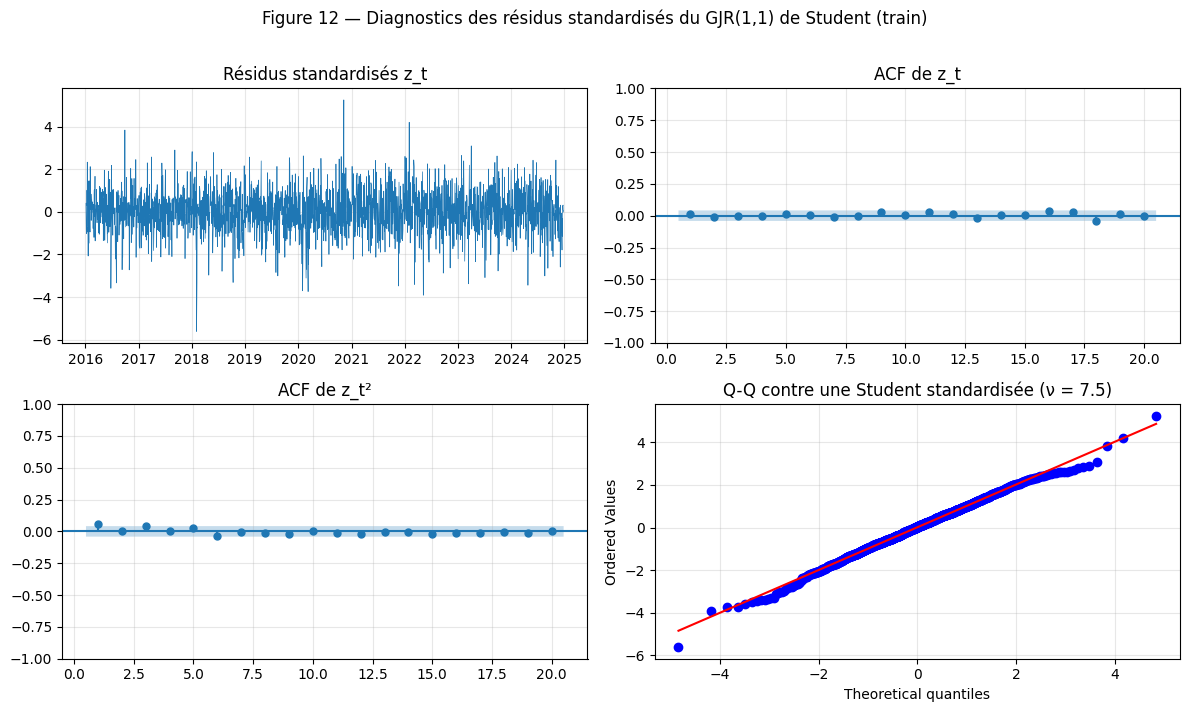

In [59]:
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats

z = pd.Series(gjr.std_resid.to_numpy(), index=dates_r)
nu = float(gjr.params["nu"])
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(z.index, z, lw=0.5, color="tab:blue")
axes[0, 0].set_title("Résidus standardisés z_t")
plot_acf(z, lags=20, zero=False, ax=axes[0, 1])
axes[0, 1].set_title("ACF de z_t")
plot_acf(z ** 2, lags=20, zero=False, ax=axes[1, 0])
axes[1, 0].set_title("ACF de z_t²")
# Q-Q contre la Student standardisée (variance 1) de ν degrés de liberté estimés.
stats.probplot(z, dist=stats.t(nu, scale=np.sqrt((nu - 2) / nu)), plot=axes[1, 1])
axes[1, 1].set_title(f"Q-Q contre une Student standardisée (ν = {nu:.1f})")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
fig.suptitle("Figure 12 — Diagnostics des résidus standardisés du GJR(1,1) de Student (train)", y=1.01)
fig.tight_layout()
save_fig(fig, 12, "garch_diagnostics")
plt.show()

**Interprétation des diagnostics des résidus standardisés (figure 12).**

**1. Plus d'autocorrélation dans la moyenne.** Ljung-Box sur z_t ne rejette pour aucun modèle (p ≈ 0,97 à 10 retards, ≈ 0,75 à 20). L'ACF de z_t est dans la bande partout.

**2. L'essentiel de l'effet ARCH a disparu, mais pas tout.**
- **Résultat global.** L'ARCH-LM(5) passe de **441** sur les rendements à **14,0** sur les z_t du GJR : le modèle a absorbé environ 97 % de la statistique.
- **Un léger effet résiduel.** Il reste significatif au seuil de 5 % pour les modèles de Student d'ordre (1,1) : ARCH-LM(5) p = 0,016 et ARCH-LM(10) p = 0,036 pour le GJR ; Ljung-Box sur z² p = 0,046 à 10 retards, mais 0,33 à 20 retards. Sur la figure, seul le premier retard de l'ACF de z² dépasse légèrement la bande (≈ 0,06).
- **Deux modèles le suppriment** : le GARCH(1,2) de Student (ARCH-LM(5) p = 0,12) et, paradoxalement, le GARCH(1,1) **normal** (p = 0,12).
- **L'explication du paradoxe.** La vraisemblance de Student accorde moins de poids aux chocs extrêmes. Elle laisse donc σ_t réagir un peu moins après eux, et une trace de regroupement subsiste dans z². Le GARCH(1,2) ajoute une seconde composante β plus lente, qui capte ce reste. Mais ses deux β ne sont pas significatifs séparément (p = 0,42 et 0,07) et son BIC est plus mauvais de 6 points.

On juge cet effet résiduel **faible et acceptable** : il est de l'ordre de 3 % de l'effet initial et disparaît à 20 retards. On ne l'élimine pas au prix d'un modèle mal identifié.

**3. La loi de Student convient.**
- **Kolmogorov-Smirnov** ne rejette pas l'adéquation de z_t à la Student estimée (p = 0,46 pour le GJR).
- **Jarque-Bera rejette toujours la normalité.** Mais l'excès de kurtosis des z_t n'est plus que de **1,5**, contre 6,6 pour les rendements bruts : le GARCH explique plus des trois quarts (78 %) de l'excès de kurtosis, et la loi de Student le reste.
- **Le graphe Q-Q** contre la Student standardisée (ν = 7,5) suit la droite sur presque tout le domaine. Seul le point le plus bas s'en écarte (z ≈ −5,6, début février 2018) : une baisse forte survenue alors que la volatilité conditionnelle n'était que de 15 % par an, donc particulièrement « surprenante » pour le modèle.

**Bilan.** Le GJR(1,1) de Student remplit les conditions essentielles : moyenne blanchie, effet ARCH réduit de 97 %, loi des innovations validée. C'est le premier modèle du projet dont les résidus sont **approximativement i.i.d.**

#### 3.3.4 Volatilité conditionnelle estimée et événements

On trace la volatilité conditionnelle annualisée, σ_t × √252, du GJR(1,1) de Student, et on la compare à la volatilité réalisée sur 21 jours du §1.5. Les deux mesures diffèrent par nature :
- la **volatilité conditionnelle** est une **prévision faite la veille**, à partir du passé seulement ;
- la **volatilité réalisée** est une **mesure a posteriori** sur les 21 derniers jours.

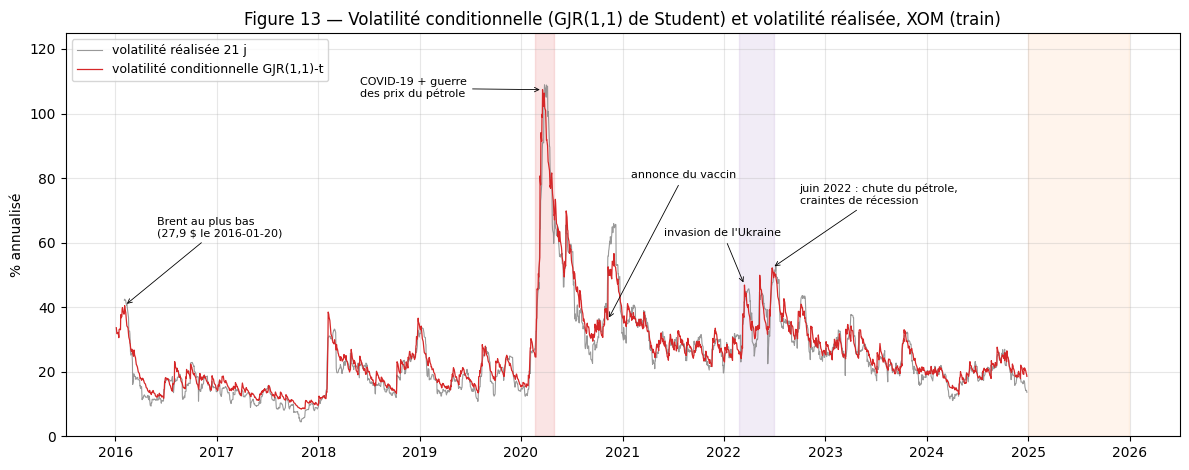

début 2016                     pic de volatilité conditionnelle :  40.5 % le 2016-02-04
mars-avril 2020                pic de volatilité conditionnelle : 107.4 % le 2020-03-19
février-mars 2022 (invasion)   pic de volatilité conditionnelle :  46.9 % le 2022-03-16
2022 entier                    pic de volatilité conditionnelle :  52.2 % le 2022-06-24
Médiane sur le train : 23.0 % ; minimum : 8.4 % le 2017-11-01
Corrélation volatilité conditionnelle / réalisée : 0.972


In [60]:
vol_c = pd.Series(gjr.conditional_volatility.to_numpy() * np.sqrt(252), index=dates_r)
vol_r = TRAIN["XOM_vol21"]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(vol_r.index, vol_r, lw=0.8, color="grey", alpha=0.8, label="volatilité réalisée 21 j")
ax.plot(vol_c.index, vol_c, lw=0.9, color="tab:red", label="volatilité conditionnelle GJR(1,1)-t")
shade(ax)
# (date du point annoté, texte, position du texte) : positions fixées à la main pour éviter les chevauchements.
events = [("2016-02-04", "Brent au plus bas\n(27,9 $ le 2016-01-20)", ("2016-06-01", 62)),
          ("2020-03-19", "COVID-19 + guerre\ndes prix du pétrole", ("2018-06-01", 105)),
          ("2020-11-09", "annonce du vaccin", ("2021-02-01", 80)),
          ("2022-03-16", "invasion de l'Ukraine", ("2021-06-01", 62)),
          ("2022-06-24", "juin 2022 : chute du pétrole,\ncraintes de récession", ("2022-10-01", 72))]
for d, txt, (tx, ty) in events:
    d = pd.Timestamp(d)
    ax.annotate(txt, xy=(d, vol_c.loc[d]), xytext=(pd.Timestamp(tx), ty), fontsize=8,
                arrowprops=dict(arrowstyle="->", lw=0.6))
ax.set_ylim(0, 125)
ax.set_ylabel("% annualisé")
ax.set_title("Figure 13 — Volatilité conditionnelle (GJR(1,1) de Student) et volatilité réalisée, XOM (train)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 13, "volatilite_conditionnelle")
plt.show()

peaks = {name: (vol_c.loc[a:b].max(), vol_c.loc[a:b].idxmax().date()) for name, (a, b) in
         {"début 2016": ("2016-01", "2016-03"), "mars-avril 2020": ("2020-03", "2020-04"),
          "février-mars 2022 (invasion)": ("2022-02-24", "2022-03-31"), "2022 entier": ("2022-01", "2022-12")}.items()}
for k, (v, d) in peaks.items():
    print(f"{k:<30} pic de volatilité conditionnelle : {v:5.1f} % le {d}")
print(f"Médiane sur le train : {vol_c.median():.1f} % ; minimum : {vol_c.min():.1f} % le {vol_c.idxmin().date()}")
print(f"Corrélation volatilité conditionnelle / réalisée : {vol_c.corr(vol_r):.3f}")

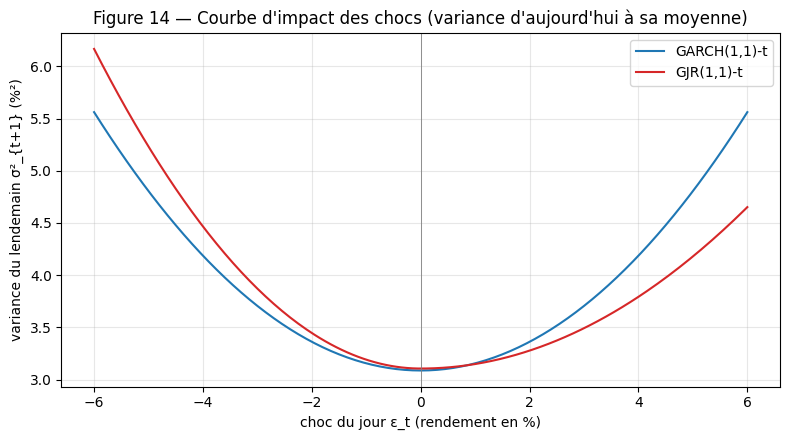

GJR : choc de −3 % → variance du lendemain 3.87 ; choc de +3 % → 3.49 (réaction aux baisses : α + γ = 0.0851 ; aux hausses : α = 0.0430)


In [61]:
# Courbe d'impact des chocs (news impact curve) : variance du lendemain selon le choc du jour.
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, res, color in (("GARCH(1,1)-t", g11, "tab:blue"), ("GJR(1,1)-t", gjr, "tab:red")):
    ni = C.news_impact(res)
    ax.plot(ni.index, ni.values, color=color, label=name)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("choc du jour ε_t (rendement en %)")
ax.set_ylabel("variance du lendemain σ²_{t+1} (%²)")
ax.set_title("Figure 14 — Courbe d'impact des chocs (variance d'aujourd'hui à sa moyenne)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 14, "courbe_impact_chocs")
plt.show()
ni = C.news_impact(gjr)
print(f"GJR : choc de −3 % → variance du lendemain {ni.loc[-3.0]:.2f} ; choc de +3 % → {ni.loc[3.0]:.2f} "
      f"(réaction aux baisses : α + γ = {gjr.params['alpha[1]'] + gjr.params['gamma[1]']:.4f} ; "
      f"aux hausses : α = {gjr.params['alpha[1]']:.4f})")

**Interprétation de la volatilité conditionnelle (figure 13) et de la courbe d'impact des chocs (figure 14).**

**Le modèle suit fidèlement la volatilité observée.** La corrélation avec la volatilité réalisée sur 21 jours est de **0,97**. La volatilité conditionnelle a une médiane de 23,0 % par an, avec un minimum de 8,4 % (2017-11-01, l'année la plus calme) et un maximum de **107,4 %** (2020-03-19).

**Lien avec les événements connus :**

| Épisode | Pic de volatilité conditionnelle | Contexte |
| --- | --- | --- |
| Début 2016 | 40,5 % le 2016-02-04 | Le pétrole touche son plus bas de la période : Brent à 27,9 $ le 2016-01-20 dans nos données. |
| Mars–avril 2020 | **107,4 %** le 2020-03-19 | Pandémie de COVID-19 et guerre des prix du pétrole (choc du 2020-03-09, `docs/sources.md`). |
| Novembre 2020 | rebond net | Annonce du vaccin le 2020-11-09. Le pic arrive **le lendemain** : σ_t se calcule avec l'information de la veille, donc la hausse de +11,9 % du 9 novembre ne se répercute que sur σ du 10. |
| Février–mars 2022 | 46,9 % le 2022-03-16 | Invasion de l'Ukraine (24 février 2022). |
| Juin 2022 | 52,2 % le 2022-06-24, pic de 2022 | Chute du pétrole et craintes de récession : le secteur de l'énergie du S&P 500 perd 16,8 % en juin 2022 ([S&P Global](https://www.spglobal.com/market-intelligence/en/news-insights/articles/2022/7/energy-stocks-plummet-in-june-as-recession-fears-drag-oil-prices-71046468)). |

Le pic de 2022 n'est donc **pas** celui de l'invasion, contrairement à ce que supposait le plan (« février–mars 2022 »). Il survient en juin, lors du retournement du marché pétrolier. On note aussi un bond début février 2018, provoqué par deux baisses consécutives de XOM (−5,2 % et −5,9 %) en période très calme.

**Une différence de nature entre les deux courbes.** La volatilité conditionnelle réagit **immédiatement** à un choc puis décroît lentement (β ≈ 0,93). La volatilité réalisée sur 21 jours monte et redescend en « créneau » : elle intègre le choc pendant exactement 21 jours, puis l'oublie d'un coup (fin 2020, par exemple). Le GARCH est une mesure **prospective** (prévue la veille), la volatilité réalisée une mesure **rétrospective**.

**Courbe d'impact des chocs (figure 14).** Elle montre la variance prévue pour demain en fonction du choc d'aujourd'hui.
- **GARCH(1,1) : courbe symétrique.** Une hausse et une baisse de même taille ont le même effet.
- **GJR(1,1) : courbe asymétrique.** Une **baisse** de 3 % porte la variance du lendemain à 3,87 %², contre 3,49 %² pour une **hausse** de 3 %. L'écart grandit avec la taille du choc : 6,2 contre 4,7 %² pour ±6 %.

C'est l'effet de levier : **les baisses accroissent davantage le risque que les hausses**.

**Rappel essentiel.** Ce modèle prévoit l'**amplitude** probable des variations de XOM, pas leur **sens**. La prévision du rendement reste nulle, puisque la moyenne retenue est la marche aléatoire. L'apport du GARCH se mesurera en section 6 sur la **qualité des intervalles de prévision** et sur la prévision de la variance, pas sur l'erreur de prévision du prix.

#### 3.3.5 Décision

| Élément | Choix | Justification |
| --- | --- | --- |
| Effets ARCH | **présents** (ARCH-LM(5) = 441) | ils justifient la modélisation de la variance |
| Loi des innovations | **Student** (ν ≈ 7,5) | +37,5 points de vraisemblance face à la normale ; KS p = 0,46 ; l'asymétrique n'apporte rien |
| Structure | **GJR(1,1)** | meilleur AIC et meilleur BIC ; effet de levier significatif (γ = 0,042, p = 0,004) ; les ordres supérieurs ne gagnent rien |
| Moyenne | **nulle** | μ non significatif (p = 0,27) ; cohérent avec la marche aléatoire du §3.1 |
| Résidus standardisés | **approximativement i.i.d.** | pas d'autocorrélation ; effet ARCH réduit de 97 % (léger reste à 5 %) ; loi de Student validée |

**Modèle retenu : marche aléatoire + GJR(1,1) à innovations de Student**, noté « ARIMA(0,1,0)-GJR-GARCH(1,1)-t ». Le GARCH(1,1) de Student, demandé par le plan, reste la référence de comparaison.

**Ce que ce modèle apporte et ce qu'il n'apporte pas.**
- **Il n'apporte rien à la prévision du prix.** La prévision ponctuelle est identique à celle de la marche aléatoire.
- **Il apporte des intervalles de prévision qui s'élargissent en période agitée et se resserrent en période calme**, au lieu d'une largeur fixe. Il fournit aussi une prévision de la variance elle-même.

**Limites à rapporter.**
1. **La persistance (≈ 0,999) est gonflée par la rupture de régime de 2020** (Lamoureux et Lastrapes, 1990). Les paramètres changent fortement entre 2016–2019 et 2021–2024 : un modèle unique sur 9 ans est une approximation. Une piste d'amélioration serait un GARCH à changement de régime, ou une ré-estimation glissante, testée en section 6.
2. **Un léger effet ARCH résiduel** subsiste au seuil de 5 %.
3. **Le modèle est univarié.** La volatilité de XLE et la corrélation dynamique XOM/XLE (DCC-GARCH) font partie des extensions de la section 7.

**Pour la section 6.** On évaluera :
- la **couverture** des intervalles à 95 % de l'ARIMA-GJR comparée à celle de l'ARIMA à variance constante ;
- la **prévision de la variance** face à r²_{t+1}, avec la perte QLIKE.